In [27]:
from scipy.stats import norm, chi2, t
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.formula.api import glm, ols
from statsmodels.api import MNLogit
import seaborn as sns
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import OLSInfluence
import statsmodels.api as sm
from statsmodels.genmod.families import Binomial, Poisson
from statsmodels.genmod.families.links import CLogLog, Probit
from itertools import product
from scipy.special import logit
from scipy.optimize import root_scalar
from math import factorial

# import custom functions
from ST5213_helpers import *

### Tutorial 2

In [2]:
df = pd.read_csv('dataset/bee.txt', sep=' ')
df['Bee'] = pd.Categorical(df['Bee'])
df['Bee'].value_counts()

Bee
Queen     35
Worker    12
Name: count, dtype: int64

In [3]:
df.head()

,Removed,Duration,Bee
1,0.07,2,Queen
2,0.10,5,Queen
3,0.11,7,Queen
4,0.12,11,Queen
5,0.15,12,Queen


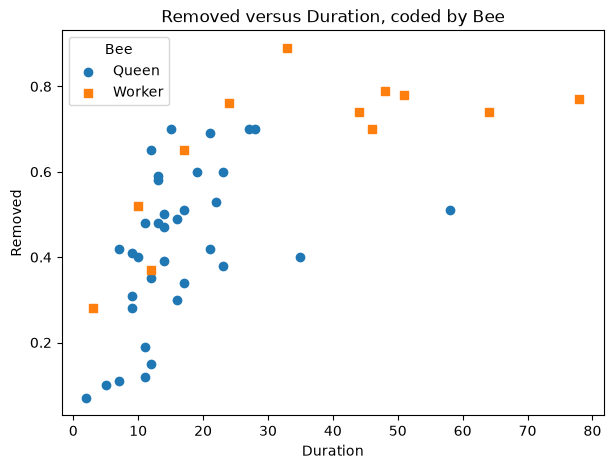

In [5]:
markers = ['o', 's']

fig, ax = plt.subplots(figsize=(7, 5))
for marker, (bee, group) in zip(markers, df.groupby('Bee')):
    ax.scatter(group['Duration'], group['Removed'], marker=marker, label=bee)

ax.set_xlabel('Duration')
ax.set_ylabel('Removed')
ax.set_title('Removed versus Duration, coded by Bee')
ax.legend(title='Bee')
plt.show()

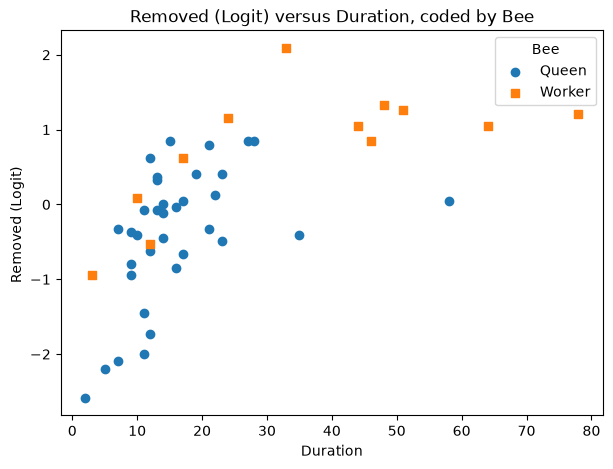

In [6]:
df['Removed_logit'] = np.log(df['Removed'] / (1 - df['Removed']))

markers = ['o', 's']

fig, ax = plt.subplots(figsize=(7, 5))
for marker, (bee, group) in zip(markers, df.groupby('Bee')):
    ax.scatter(group['Duration'], group['Removed_logit'], marker=marker, label=bee)

ax.set_xlabel('Duration')
ax.set_ylabel('Removed (Logit) ')
ax.set_title('Removed (Logit) versus Duration, coded by Bee')
ax.legend(title='Bee')
plt.show()

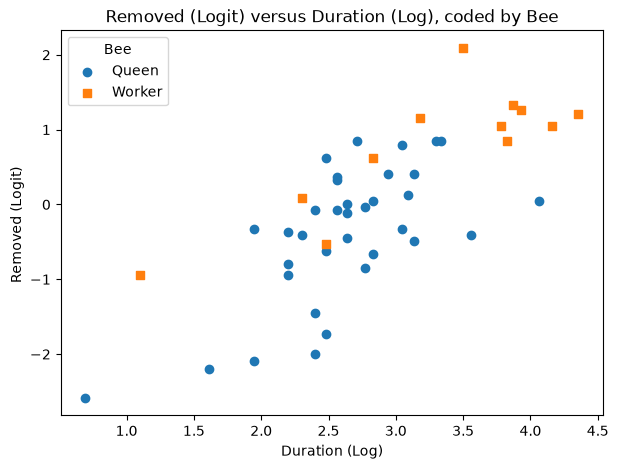

In [7]:
df['Duration_log'] = np.log(df['Duration'])

markers = ['o', 's']

fig, ax = plt.subplots(figsize=(7, 5))
for marker, (bee, group) in zip(markers, df.groupby('Bee')):
    ax.scatter(group['Duration_log'], group['Removed_logit'], marker=marker, label=bee)

ax.set_xlabel('Duration (Log)')
ax.set_ylabel('Removed (Logit) ')
ax.set_title('Removed (Logit) versus Duration (Log), coded by Bee')
ax.legend(title='Bee')
plt.show()

In [8]:
fm = ols(formula='Removed_logit ~ Duration_log * Bee', data=df).fit()
print(fm.summary2(),'\n')

                     Results: Ordinary least squares
Model:                 OLS                 Adj. R-squared:        0.588   
Dependent Variable:    Removed_logit       AIC:                   97.0709 
Date:                  2026-11-23 11:36    BIC:                   104.4715
No. Observations:      47                  Log-Likelihood:        -44.535 
Df Model:              3                   F-statistic:           22.90   
Df Residuals:          43                  Prob (F-statistic):    5.15e-09
R-squared:             0.615               Scale:                 0.42579 
--------------------------------------------------------------------------
                            Coef.  Std.Err.    t    P>|t|   [0.025  0.975]
--------------------------------------------------------------------------
Intercept                  -3.0390   0.5115 -5.9413 0.0000 -4.0705 -2.0074
Bee[T.Worker]               1.3770   0.8722  1.5788 0.1217 -0.3819  3.1359
Duration_log                1.0121   0.1902  5.

In [9]:
fm = ols(formula='Removed_logit ~ Duration_log + Bee', data=df).fit()
print(fm.summary2(),'\n')

                 Results: Ordinary least squares
Model:              OLS              Adj. R-squared:     0.589   
Dependent Variable: Removed_logit    AIC:                96.0711 
Date:               2026-11-23 11:37 BIC:                101.6216
No. Observations:   47               Log-Likelihood:     -45.036 
Df Model:           2                F-statistic:        33.95   
Df Residuals:       44               Prob (F-statistic): 1.21e-09
R-squared:          0.607            Scale:              0.42507 
-----------------------------------------------------------------
                   Coef.  Std.Err.    t    P>|t|   [0.025  0.975]
-----------------------------------------------------------------
Intercept         -2.7146   0.3842 -7.0650 0.0000 -3.4890 -1.9402
Bee[T.Worker]      0.5697   0.2364  2.4095 0.0202  0.0932  1.0462
Duration_log       0.8886   0.1402  6.3391 0.0000  0.6061  1.1711
-----------------------------------------------------------------
Omnibus:               1.29

In [2]:
df = pd.read_csv('dataset/michiganacc.txt', sep='\t')
df['Season'] = pd.Categorical(df['Season'])
df['Month'] = pd.Categorical(df['Month'])
df.head()

,Time,Season,Month,Unemployment_rate,Accidents
0,1,Winter,January,8.00,40
1,2,Winter,February,8.20,39
2,3,Spring,March,8.00,32
3,4,Spring,April,8.75,27
4,5,Spring,May,7.25,31


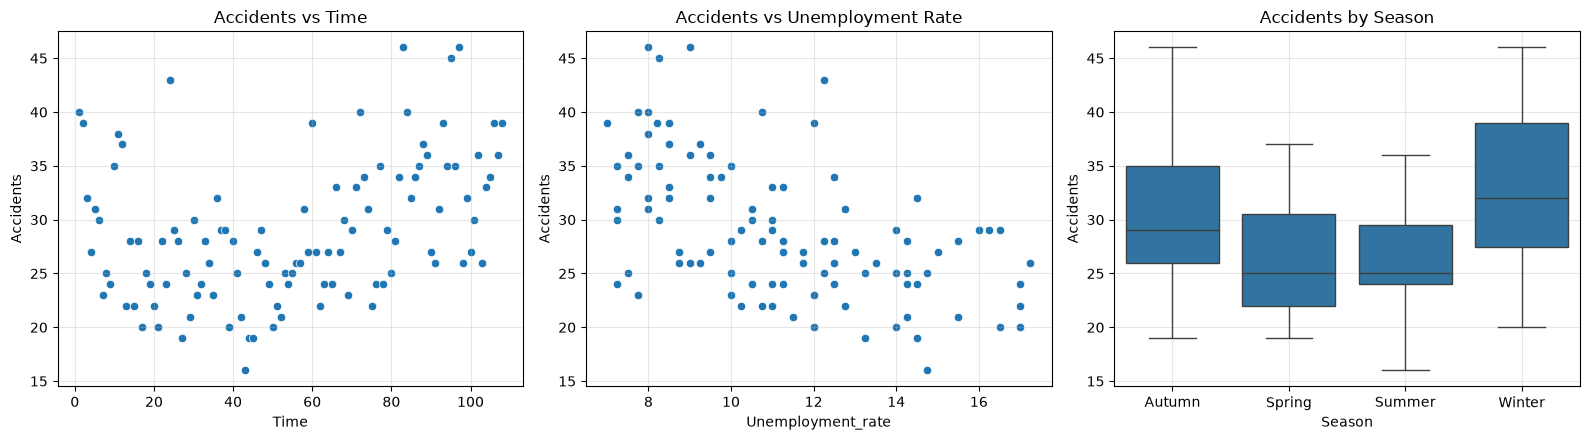

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Accidents vs Time
sns.scatterplot(data=df, x='Time', y='Accidents', ax=axes[0])
axes[0].set_title('Accidents vs Time')

# 2. Accidents vs Unemployment Rate
sns.scatterplot(data=df, x='Unemployment_rate', y='Accidents', ax=axes[1])
axes[1].set_title('Accidents vs Unemployment Rate')

# 3. Accidents by Season
sns.boxplot(data=df, x='Season', y='Accidents', ax=axes[2])
axes[2].set_title('Accidents by Season')

# Formatting
for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [4]:
fm_main = ols(formula='Accidents ~ Time + Unemployment_rate + Season', data=df).fit()
print(fm_main.summary2(),'\n')

                 Results: Ordinary least squares
Model:              OLS              Adj. R-squared:     0.484   
Dependent Variable: Accidents        AIC:                645.1252
Date:               2026-11-23 11:54 BIC:                661.2180
No. Observations:   108              Log-Likelihood:     -316.56 
Df Model:           5                F-statistic:        21.07   
Df Residuals:       102              Prob (F-statistic): 2.05e-14
R-squared:          0.508            Scale:              21.792  
-----------------------------------------------------------------
                   Coef.  Std.Err.    t    P>|t|   [0.025  0.975]
-----------------------------------------------------------------
Intercept         40.5173   2.4070 16.8328 0.0000 35.7429 45.2916
Season[T.Spring]  -2.4183   1.2839 -1.8836 0.0625 -4.9648  0.1283
Season[T.Summer]  -3.6858   1.2745 -2.8921 0.0047 -6.2137 -1.1579
Season[T.Winter]   3.2863   1.2859  2.5557 0.0121  0.7357  5.8368
Time               0.0435  

In [5]:
fm1 = ols(formula='Accidents ~ Time + Unemployment_rate', data=df).fit()
anova_lm(fm1, fm_main)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,105.0,2984.349062,0.0,NaN,NaN,NaN
1,102.0,2222.803936,3.0,761.545126,11.648591,0.000001


In [7]:
fm = ols(formula='Accidents ~ (Time + Unemployment_rate + Season)**2', data=df).fit()
drop1_lm(fm)

,Df,RSS,AIC,F,Pr(>F)
<none>,,2102.268794,653.103972,,
Time:Season,3,2194.832248,651.757528,1.394292,0.249334
Unemployment_rate:Season,3,2123.900506,648.209581,0.32584,0.806667
Time:Unemployment_rate,1,2102.276572,651.104371,0.000351,0.985082


In [9]:
fm = ols(formula='Accidents ~ Time*Season + Unemployment_rate*Season', data=df).fit()
drop1_lm(fm)

,Df,RSS,AIC,F,Pr(>F)
<none>,,2102.276572,651.104371,,
Time:Season,3,2196.938927,649.861140,1.440912,0.235695
Unemployment_rate:Season,3,2124.520819,646.241119,0.338593,0.797458


In [12]:
fm = ols(formula='Accidents ~ Time*Season + Unemployment_rate', data=df).fit()
drop1_lm(fm)

,Df,RSS,AIC,F,Pr(>F)
<none>,,2124.520819,646.241119,,
Time:Season,3,2222.803936,645.125220,1.526623,0.212333
Unemployment_rate,1,3128.944798,686.053270,46.804895,0.0


In [14]:
fm = ols(formula='Accidents ~ Time + Unemployment_rate + Season', data=df).fit()
drop1_lm(fm)

,Df,RSS,AIC,F,Pr(>F)
<none>,,2222.803936,645.125220,,
Season,3,2984.349062,670.943339,11.648591,0.000001
Time,1,2405.248914,651.644688,8.372033,0.004659
Unemployment_rate,1,3236.429285,683.700951,46.513228,0.0


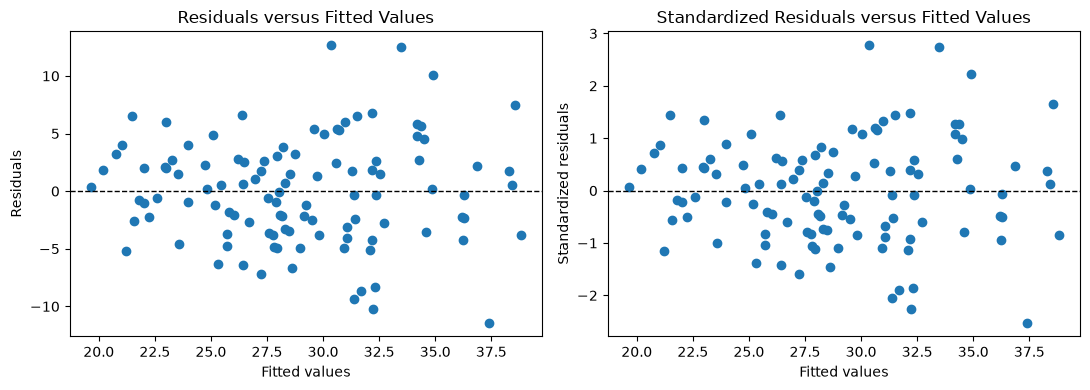

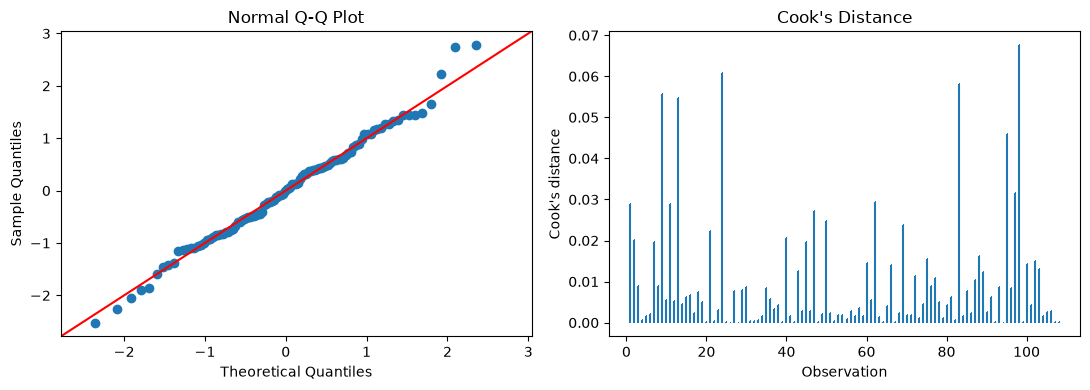

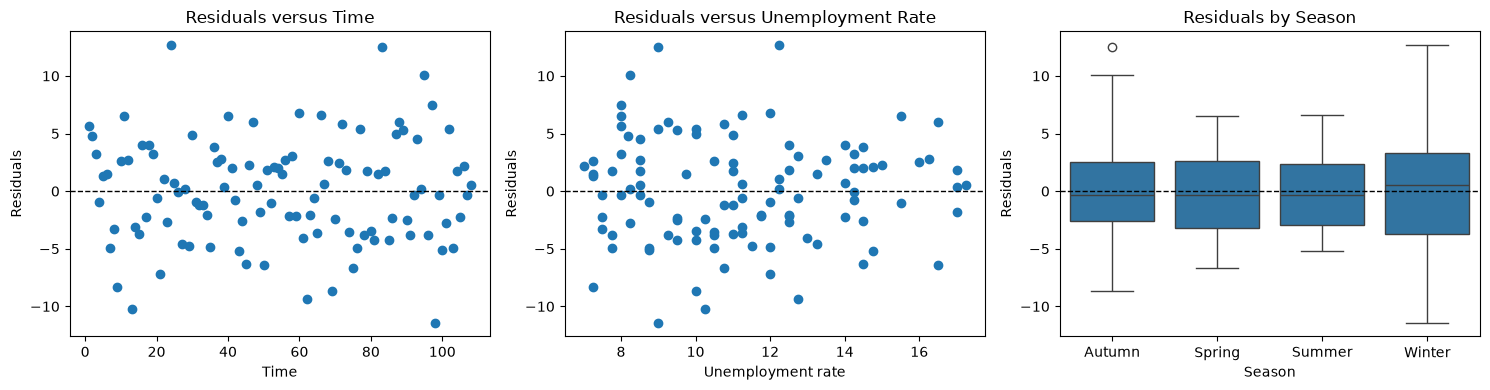

In [17]:
# Residual and influence quantities for the selected model fm
fitted_values = fm.fittedvalues
residuals = fm.resid
influence = OLSInfluence(fm)
standardized_residuals = influence.resid_studentized_internal
cooks_distance = influence.cooks_distance[0]

# Residuals and fitted values
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(11, 4))
axes[0].scatter(fitted_values, residuals)
axes[0].axhline(0, color='black', linestyle='--', linewidth=1)
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals versus Fitted Values')

axes[1].scatter(fitted_values, standardized_residuals)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_xlabel('Fitted values')
axes[1].set_ylabel('Standardized residuals')
axes[1].set_title('Standardized Residuals versus Fitted Values')
plt.tight_layout()
plt.show()

# Q-Q plot and Cook's distance
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(11, 4))
sm.qqplot(standardized_residuals, line='45', ax=axes[0])
axes[0].set_title('Normal Q-Q Plot')

observation_numbers = np.arange(1, len(cooks_distance) + 1)
axes[1].stem(observation_numbers, cooks_distance, markerfmt=',', basefmt=' ')
axes[1].set_xlabel('Observation')
axes[1].set_ylabel("Cook's distance")
axes[1].set_title("Cook's Distance")
plt.tight_layout()
plt.show()

# Residuals against the continuous and categorical predictors
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4))
axes[0].scatter(df['Time'], residuals)
axes[0].axhline(0, color='black', linestyle='--', linewidth=1)
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals versus Time')

axes[1].scatter(df['Unemployment_rate'], residuals)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_xlabel('Unemployment rate')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residuals versus Unemployment Rate')

sns.boxplot(data=df.assign(Residuals=residuals), x='Season', y='Residuals', ax=axes[2])
axes[2].axhline(0, color='black', linestyle='--', linewidth=1)
axes[2].set_title('Residuals by Season')
plt.tight_layout()
plt.show()

### Tutorial 3

In [18]:
np.exp(-0.4284+0.5893*2.44)

np.float64(2.744206603911697)

In [19]:
np.exp(0.5893)

np.float64(1.8027260653811303)

In [20]:
0.5893-1.96*0.065, 0.5893+1.96*0.065

(0.46190000000000003, 0.7167000000000001)

In [21]:
0.5893/0.065

9.066153846153847

In [23]:
2 * t.sf(9.066, 171)

np.float64(2.819567144661557e-16)

### Tutorial 4

In [26]:
df = pd.read_csv('dataset/donnerparty.txt', sep=' ')
df['Sex'] = pd.Categorical(df['Sex'])
df['Status'] = pd.Categorical(df['Status'], categories=['Survived', 'Died'], ordered=True)
df.head()

,Age,Sex,Status
1,23,Male,Died
2,40,Female,Survived
3,40,Male,Survived
4,30,Male,Died
5,28,Male,Died


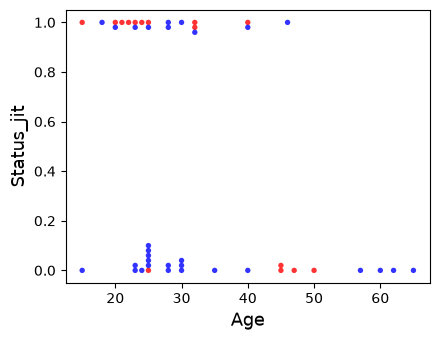

In [35]:
# Sort dataFrame by Age (young to old), and then Sex (female then male) and relabel rows
df_plot = df.copy()
df_plot = df_plot.sort_values(by=['Age', 'Sex']).reset_index(drop=True)

# Create a new variable called Survjit in dataframe
df_plot['Status_num'] = df_plot['Status'].map({'Survived': 1, 'Died': 0})
df_plot['Status_jit'] = df_plot['Status_num'].astype(float)

# create jitter sequence 
jit = df_plot.groupby(['Age', 'Status_num']).cumcount() * 0.02

#  Apply jitter to spread overlapping data points upward from 0 or downward from 1
df_plot.loc[df_plot['Status_num'] == 0, 'Status_jit'] += jit
df_plot.loc[df_plot['Status_num'] == 1, 'Status_jit'] -= jit

fig, ax = plt.subplots(figsize=(4.5, 3.5))
colors = ['red' if s == 'Female' else 'blue' for s in df_plot['Sex']]

ax.scatter(df_plot['Age'], df_plot['Status_jit'], c=colors, alpha=0.8, edgecolors='none', s=15)
ax.set_xlabel('Age', fontsize=13)
ax.set_ylabel('Status_jit', fontsize=13)

plt.tight_layout()
plt.show()

In [28]:
fm = glm('Status ~ Age + Sex', df, family=Binomial()).fit()
print(fm.summary2(),'\n')

                       Results: Generalized linear model
Model:              GLM                                  Method:         IRLS   
Model Family:       Binomial                             AIC:            57.2563
Link Function:      Logit                                BIC:            62.6763
Dependent Variable: ['Status[Survived]', 'Status[Died]'] Log-Likelihood: -25.628
Date:               2026-11-23 15:46                     LL-Null:        -30.913
No. Observations:   45                                   Deviance:       51.256 
Df Model:           2                                    Pearson chi2:   44.4   
Df Residuals:       42                                   Scale:          1.0000 
------------------------------------------------------------------------------------
                  Coef.      Std.Err.        z        P>|z|       [0.025      0.975]
------------------------------------------------------------------------------------
Intercept         3.2304       1.3870   

In [36]:
3.2304-1.5973

1.6331

In [37]:
df['Age'].describe()

count    45.000000
mean     31.800000
std      12.511086
min      15.000000
25%      24.000000
50%      28.000000
75%      40.000000
max      65.000000
Name: Age, dtype: float64

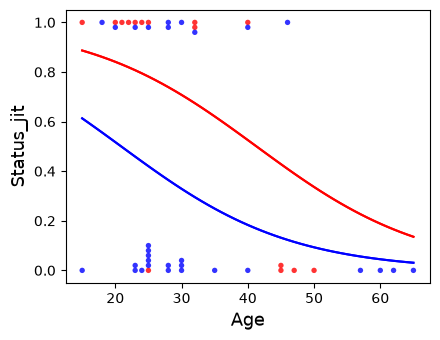

<Figure size 640x480 with 0 Axes>

In [39]:
ages = np.arange(15, 66)

# Build the new dataframes for prediction
pred_m_df = pd.DataFrame({'Age': ages, 'Sex': 'Male'})
pred_f_df = pd.DataFrame({'Age': ages, 'Sex': 'Female'})

# Compute predicted values on the response scale
pred_m = fm.predict(pred_m_df)
pred_f = fm.predict(pred_f_df)

ax.plot(ages, pred_m, color="blue")
ax.plot(ages, pred_f, color="red")

plt.tight_layout()

from IPython.display import display
display(fig)

In [29]:
np.exp(0.0782*30)

np.float64(10.443711218652142)

In [30]:
np.exp(1.5973)

np.float64(4.939677274414974)

In [33]:
fm_full = glm('Status ~ Age * Sex', df, family=Binomial()).fit()
anova_nested(fm, fm_full)

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
Model 1,42.0,51.256285,NaN,NaN,NaN
Model 2,41.0,47.346366,1.0,3.909918,0.048002


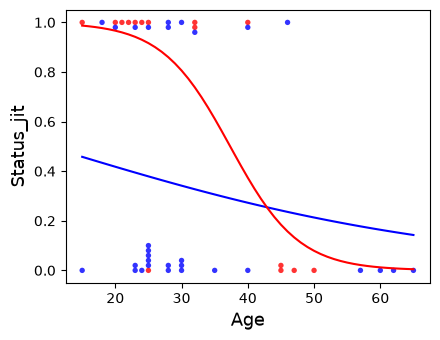

In [40]:
pred_m_full = fm_full.predict(pred_m_df)
pred_f_full = fm_full.predict(pred_f_df)

fig, ax = plt.subplots(figsize=(4.5, 3.5))

ax.scatter(df_plot['Age'], df_plot['Status_jit'], c=colors, alpha=0.8, edgecolors='none', s=15)
ax.set_xlabel('Age', fontsize=13)
ax.set_ylabel('Status_jit', fontsize=13)

ax.plot(ages, pred_m_full, color="blue")
ax.plot(ages, pred_f_full, color="red")

plt.tight_layout()
plt.show()

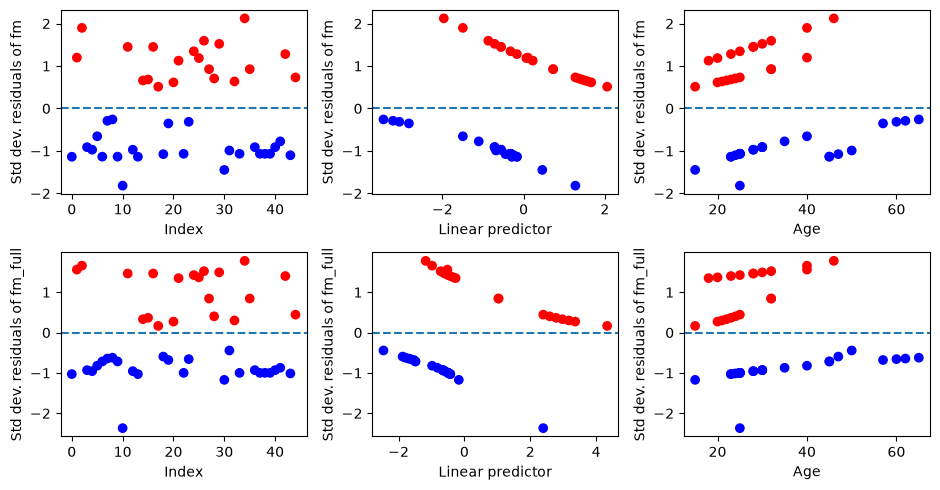

In [34]:
res_deviance_std = fm.resid_deviance / np.sqrt(1 - hat_diag(fm))
res_deviance_std_full = fm_full.resid_deviance / np.sqrt(1 - hat_diag(fm_full))

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(9.5, 5))

colors = ['red' if s > 0 else 'blue' for s in res_deviance_std]
colors_full = ['red' if s > 0 else 'blue' for s in res_deviance_std_full]

axes[0,0].scatter(range(len(df)), res_deviance_std, color=colors)
axes[0,0].axhline(0, linestyle='--')
axes[0,0].set_xlabel("Index")
axes[0,0].set_ylabel("Std dev. residuals of fm")

axes[0,1].scatter(fm.predict(df, which='linear'), res_deviance_std, color=colors)
axes[0,1].axhline(0, linestyle='--')
axes[0,1].set_xlabel("Linear predictor")
axes[0,1].set_ylabel("Std dev. residuals of fm")
    
axes[0,2].scatter(df['Age'], res_deviance_std, color=colors)
axes[0,2].axhline(0, linestyle='--')
axes[0,2].set_xlabel("Age")
axes[0,2].set_ylabel("Std dev. residuals of fm")

axes[1,0].scatter(range(len(df)), res_deviance_std_full, color=colors_full)
axes[1,0].axhline(0, linestyle='--')
axes[1,0].set_xlabel("Index")
axes[1,0].set_ylabel("Std dev. residuals of fm_full")

axes[1,1].scatter(fm_full.predict(df, which='linear'), res_deviance_std_full, color=colors_full)
axes[1,1].axhline(0, linestyle='--')
axes[1,1].set_xlabel("Linear predictor")
axes[1,1].set_ylabel("Std dev. residuals of fm_full")
    
axes[1,2].scatter(df['Age'], res_deviance_std_full, color=colors_full)
axes[1,2].axhline(0, linestyle='--')
axes[1,2].set_xlabel("Age")
axes[1,2].set_ylabel("Std dev. residuals of fm_full")

plt.tight_layout()
plt.show()

### Tutorial 5

In [ ]:
df = pd.read_csv('dataset/beetles.txt', sep=' ')
df.head()

,Dose,Exposed,Mortality
0,1.6907,59,6
1,1.7242,60,13
2,1.7552,62,18
3,1.7842,56,28
4,1.8113,63,52


In [44]:
df2 = pd.read_csv('dataset/beetles2.txt', sep=' ')
print(df2['Status'].value_counts())
df2['Status'] = pd.Categorical(df2['Status'], categories=['Died', 'Survived'], ordered=True)
df2.head()

Status
Died        291
Survived    190
Name: count, dtype: int64


,Dose,Status
0,1.6907,Died
1,1.6907,Died
2,1.6907,Died
3,1.6907,Died
4,1.6907,Died


In [59]:
df['failure'] = df['Exposed'] - df['Mortality']

fm = glm('Mortality + failure ~ Dose', df, family=Binomial()).fit()
print(fm.summary2(),'\n')

                 Results: Generalized linear model
Model:              GLM                      Method:         IRLS   
Model Family:       Binomial                 AIC:            41.4303
Link Function:      Logit                    BIC:            41.5892
Dependent Variable: ['Mortality', 'failure'] Log-Likelihood: -18.715
Date:               2026-11-23 17:01         LL-Null:        -155.20
No. Observations:   8                        Deviance:       11.232 
Df Model:           1                        Pearson chi2:   10.0   
Df Residuals:       6                        Scale:          1.0000 
---------------------------------------------------------------------
              Coef.    Std.Err.     z      P>|z|    [0.025    0.975] 
---------------------------------------------------------------------
Intercept    -60.7175    5.1807  -11.7199  0.0000  -70.8715  -50.5634
Dose          34.2703    2.9121   11.7681  0.0000   28.5626   39.9780
 



In [60]:
chi2.sf(fm.deviance, fm.df_resid)

np.float64(0.08145880992733505)

In [46]:
fm2 = glm('Status ~ Dose', df2, family=Binomial()).fit()
print(fm2.summary2(),'\n')

                        Results: Generalized linear model
Model:              GLM                                  Method:         IRLS    
Model Family:       Binomial                             AIC:            376.4708
Link Function:      Logit                                BIC:            384.8225
Dependent Variable: ['Status[Died]', 'Status[Survived]'] Log-Likelihood: -186.24 
Date:               2026-11-23 16:36                     LL-Null:        -322.72 
No. Observations:   481                                  Deviance:       372.47  
Df Model:           1                                    Pearson chi2:   436.    
Df Residuals:       479                                  Scale:          1.0000  
-------------------------------------------------------------------------------------
               Coef.       Std.Err.        z         P>|z|       [0.025       0.975] 
-------------------------------------------------------------------------------------
Intercept     -60.7175      

In [48]:
fm = glm('Mortality + failure ~ Dose', df, family=Binomial(link=CLogLog())).fit()
fm2 = update_glm(fm, add='I(Dose**2)')
fm3 = update_glm(fm2, add='I(Dose**3)')

In [49]:
print(fm.summary2(),'\n')

                 Results: Generalized linear model
Model:              GLM                      Method:         IRLS   
Model Family:       Binomial                 AIC:            33.6445
Link Function:      CLogLog                  BIC:            33.8034
Dependent Variable: ['Mortality', 'failure'] Log-Likelihood: -14.822
Date:               2026-11-23 16:45         LL-Null:        -155.20
No. Observations:   8                        Deviance:       3.4464 
Df Model:           1                        Pearson chi2:   3.29   
Df Residuals:       6                        Scale:          1.0000 
---------------------------------------------------------------------
              Coef.    Std.Err.     z      P>|z|    [0.025    0.975] 
---------------------------------------------------------------------
Intercept    -39.5723    3.2403  -12.2126  0.0000  -45.9231  -33.2215
Dose          22.0412    1.7994   12.2495  0.0000   18.5145   25.5678
 



In [50]:
print(fm2.summary2(),'\n')

                 Results: Generalized linear model
Model:              GLM                      Method:         IRLS   
Model Family:       Binomial                 AIC:            35.6087
Link Function:      CLogLog                  BIC:            35.8470
Dependent Variable: ['Mortality', 'failure'] Log-Likelihood: -14.804
Date:               2026-11-23 16:47         LL-Null:        -155.20
No. Observations:   8                        Deviance:       3.4106 
Df Model:           2                        Pearson chi2:   3.26   
Df Residuals:       5                        Scale:          1.0000 
--------------------------------------------------------------------
                  Coef.   Std.Err.    z    P>|z|    [0.025   0.975] 
--------------------------------------------------------------------
Intercept        -19.0178 108.1390 -0.1759 0.8604 -230.9664 192.9308
Dose              -0.9678 121.0657 -0.0080 0.9936 -238.2523 236.3166
I(Dose ** 2)       6.4349  33.8700  0.1900 0.8493  -

In [51]:
print(fm3.summary2(),'\n')

                  Results: Generalized linear model
Model:                GLM                      Method:         IRLS   
Model Family:         Binomial                 AIC:            37.3434
Link Function:        CLogLog                  BIC:            37.6611
Dependent Variable:   ['Mortality', 'failure'] Log-Likelihood: -14.672
Date:                 2026-11-23 16:47         LL-Null:        -155.20
No. Observations:     8                        Deviance:       3.1453 
Df Model:             3                        Pearson chi2:   3.00   
Df Residuals:         4                        Scale:          1.0000 
----------------------------------------------------------------------
               Coef.     Std.Err.    z    P>|z|     [0.025     0.975] 
----------------------------------------------------------------------
Intercept     1740.0153 3265.4474  0.5329 0.5941  -4660.1440 8140.1747
Dose         -2960.6274 5487.1445 -0.5396 0.5895 -13715.2331 7793.9782
I(Dose ** 2)  1665.4649 3

In [52]:
anova_nested(fm, fm2, fm3)

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
Model 1,6.0,3.446439,NaN,NaN,NaN
Model 2,5.0,3.410621,1.0,0.035818,0.849892
Model 3,4.0,3.145312,1.0,0.265308,0.606496


In [53]:
beta = np.array(fm.params)

def LD(p):
    zeta = np.log(-np.log(1-p))
    return (zeta - beta[0]) / beta[1]

print('LD50:', LD(0.5))  
print('LD90:', LD(0.9))  
print('min Dose:', min(df['Dose']), ', max Dose:', max(df['Dose']))

LD50: 1.778753033557946
LD90: 1.8332213484353996
min Dose: 1.6907 , max Dose: 1.8839


In [54]:
def compute_LD_CI(x, beta):
    
    h = np.array([-1/beta[1], -x/beta[1]])
    sd_x = np.sqrt(h @ np.array(fm.cov_params()) @ h)
    return x + np.array([-1,1]) * norm.ppf(0.975) * sd_x

LD50_CI = compute_LD_CI(LD(0.5), beta)
print(LD50_CI)

LD90_CI = compute_LD_CI(LD(0.9), beta)
print(LD90_CI)

[1.77090037 1.78660569]
[1.82440954 1.84203315]


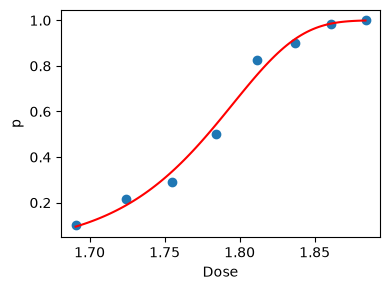

In [57]:
df['prop'] = df['Mortality'] / df['Exposed']
doses = np.linspace(min(df['Dose']), max(df['Dose']), 100)
pred_df = pd.DataFrame({'Dose': doses})

plt.figure(figsize=(4, 3))
plt.scatter(df['Dose'], df['prop'])
plt.plot(doses, fm.predict(pred_df), 'r-')
plt.xlabel('Dose')
plt.ylabel('p')
plt.tight_layout()  

plt.show()

In [55]:
fm_logit = glm('Mortality + failure ~ Dose', df, family=Binomial()).fit()
fm_logit2 = update_glm(fm_logit, add='I(Dose**2)')
fm_logit3 = update_glm(fm_logit2, add='I(Dose**3)')
anova_nested(fm_logit, fm_logit2, fm_logit3)

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
Model 1,6.0,11.232231,NaN,NaN,NaN
Model 2,5.0,3.194905,1.0,8.037326,0.004582
Model 3,4.0,2.921361,1.0,0.273544,0.600964


In [56]:
fm.aic, fm_logit2.aic

(np.float64(33.64447695011708), np.float64(35.39294350272907))

### Assignment 1

In [2]:
z = -1.2
print(2*(1-norm.cdf(abs(z))))

0.23013934044341644


In [4]:
n=31
y_sum=6+4+3+8+8+11
p_hat = 1/(1+y_sum/n)

def ll(p):
    return n*np.log(p) + y_sum*np.log(1-p)

X2 = 2*(ll(p_hat) - ll(0.5))
print(X2)
print(chi2.sf(X2, 1))

1.143920106839417
0.2848255105328944


### Tutorial 6

In [38]:
df = pd.read_csv('dataset/snails.txt', sep=' ')
df['Species'] = pd.Categorical(df['Species'])
df['Exposure'] = pd.Categorical(df['Exposure'], categories=[4, 1, 2, 3], ordered=True)
df['Rel_Hum'] = pd.Categorical(df['Rel_Hum'])
df['Temp'] = pd.Categorical(df['Temp'])
df['Survival'] = df['N'] - df['Deaths']
df.head()

,Species,Exposure,Rel_Hum,Temp,Deaths,N,Survival
1,A,1,60.0,10,0,20,20
2,A,1,60.0,15,0,20,20
3,A,1,60.0,20,0,20,20
4,A,1,65.8,10,0,20,20
5,A,1,65.8,15,0,20,20


In [53]:
df.pivot_table(index='Species', columns='Exposure', values='Deaths', aggfunc='sum')

Exposure,4,1,2,3
Species,,,,
A,55,0,3,24
B,113,0,11,69


In [54]:
df.pivot_table(index='Species', columns='Rel_Hum', values='Deaths', aggfunc='sum')

Rel_Hum,60.0,65.8,70.5,75.8
Species,,,,
A,33,22,16,11
B,76,55,34,28


In [55]:
df.pivot_table(index='Species', columns='Temp', values='Deaths', aggfunc='sum')

Temp,10,15,20
Species,,,
A,17,28,37
B,47,66,80


In [56]:
fm = glm('Survival + Deaths ~ (Species + Exposure + Rel_Hum + Temp)**4', df, family=Binomial()).fit()
res = stepAIC(fm, verbose=True)

c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linea

Start AIC: 350.862599
Start formula: Survival + Deaths ~ (Species + Exposure + Rel_Hum + Temp)**4
Best drop: Species:Exposure:Rel_Hum:Temp -> AIC 317.451390 (improve 33.4112)
Best drop: Exposure:Rel_Hum:Temp -> AIC 289.592050 (improve 27.8593)
Best drop: Species:Exposure:Rel_Hum -> AIC 274.322339 (improve 15.2697)
Best drop: Exposure:Rel_Hum -> AIC 257.887632 (improve 16.4347)
Best drop: Species:Rel_Hum:Temp -> AIC 246.943326 (improve 10.9443)
Best drop: Rel_Hum:Temp -> AIC 236.182452 (improve 10.7609)
Best drop: Species:Exposure:Temp -> AIC 228.911873 (improve 7.27058)
Best drop: Species:Exposure -> AIC 223.283511 (improve 5.62836)
Best drop: Exposure:Temp -> AIC 218.052501 (improve 5.23101)
Best drop: Species:Rel_Hum -> AIC 213.642921 (improve 4.40958)
Best drop: Species:Temp -> AIC 209.669114 (improve 3.97381)
Best drop: Temp -> AIC 230.482798 (improve -20.8137)


In [57]:
res.selected_formula

'Survival + Deaths ~ Species + Exposure + Rel_Hum + Temp'

In [58]:
drop1_glm(res.model)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,30.806516,209.669114,,
Species,1,100.262384,277.124983,69.455868,0.0
Exposure,3,416.152565,589.015164,385.34605,0.0
Rel_Hum,3,95.289595,268.152194,64.48308,0.0
Temp,2,55.620199,230.482798,24.813684,0.000004


In [61]:
fm = glm('Survival + Deaths ~ (Species + Exposure + Rel_Hum + Temp)**4', df, family=Binomial()).fit()
drop1_glm(fm)

c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linea

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,4.757317e-09,350.862599,,
Species:Exposure:Rel_Hum:Temp,18,2.588791e+00,317.451390,2.588791,0.999991


In [62]:
fm = update_glm(fm, drop='Species:Exposure:Rel_Hum:Temp')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,2.588791,317.451390,,
Species:Exposure:Rel_Hum,9,4.291460,301.154059,1.702669,0.995346
Species:Exposure:Temp,6,7.268328,310.130927,4.679537,0.585521
Species:Rel_Hum:Temp,6,3.809641,306.672240,1.220849,0.975842
Exposure:Rel_Hum:Temp,18,10.729451,289.592050,8.14066,0.976468


In [63]:
fm = update_glm(fm, drop='Species:Exposure:Rel_Hum')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,4.291460,301.154059,,
Species:Exposure:Temp,6,9.542260,294.404859,5.2508,0.512072
Species:Rel_Hum:Temp,6,5.331010,290.193608,1.03955,0.984069
Exposure:Rel_Hum:Temp,18,13.459741,274.322339,9.16828,0.955716


In [ ]:
fm = update_glm(fm, drop='Species:Rel_Hum:Temp')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,5.331010,290.193608,,
Species:Rel_Hum,3,6.779668,285.642267,1.448659,0.69417
Species:Exposure:Temp,6,10.265017,283.127616,4.934007,0.552305
Exposure:Rel_Hum:Temp,18,14.559877,263.422476,9.228868,0.954203


In [65]:
fm = update_glm(fm, drop='Exposure:Rel_Hum:Temp')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,14.559877,263.422476,,
Species:Rel_Hum,3,15.871463,258.734062,1.311586,0.726384
Exposure:Rel_Hum,9,16.080727,246.943326,1.52085,0.996989
Rel_Hum:Temp,6,15.860292,252.722890,1.300415,0.971635
Species:Exposure:Temp,6,19.355910,256.218508,4.796032,0.570227


In [66]:
fm = update_glm(fm, drop='Exposure:Rel_Hum')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,16.080727,246.943326,,
Species:Rel_Hum,3,17.413432,242.276031,1.332705,0.721382
Rel_Hum:Temp,6,17.319853,236.182452,1.239126,0.974908
Species:Exposure:Temp,6,20.838147,239.700745,4.75742,0.575281


In [67]:
fm = update_glm(fm, drop='Rel_Hum:Temp')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,17.319853,236.182452,,
Species:Rel_Hum,3,18.791549,231.654148,1.471696,0.688818
Species:Exposure:Temp,6,22.049275,228.911873,4.729421,0.578955


In [68]:
fm = update_glm(fm, drop='Species:Rel_Hum')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,18.791549,231.654148,,
Rel_Hum,3,83.129867,289.992465,64.338318,0.0
Species:Exposure:Temp,6,23.582689,224.445287,4.79114,0.570867


In [69]:
fm = update_glm(fm, drop='Species:Exposure:Temp')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,23.582689,224.445287,,
Rel_Hum,3,87.978375,282.840974,64.395687,0.0
Species:Exposure,3,24.095522,218.958120,0.512833,0.916063
Species:Temp,2,23.847665,220.710263,0.264976,0.875913
Exposure:Temp,6,30.511718,219.374316,6.929029,0.32746


In [70]:
fm = update_glm(fm, drop='Species:Exposure')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,24.095522,218.958120,,
Rel_Hum,3,88.630134,277.492732,64.534612,0.0
Species:Temp,2,24.265135,215.127734,0.169614,0.91869
Exposure:Temp,6,30.780323,213.642921,6.684801,0.350982


In [71]:
fm = update_glm(fm, drop='Species:Temp')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,24.265135,215.127734,,
Species,1,93.742479,282.605078,69.477344,0.0
Rel_Hum,3,88.817122,273.679721,64.551987,0.0
Exposure:Temp,6,30.806516,209.669114,6.541381,0.365347


In [72]:
fm = update_glm(fm, drop='Exposure:Temp')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,30.806516,209.669114,,
Species,1,100.262384,277.124983,69.455868,0.0
Exposure,3,416.152565,589.015164,385.34605,0.0
Rel_Hum,3,95.289595,268.152194,64.48308,0.0
Temp,2,55.620199,230.482798,24.813684,0.000004


In [73]:
chi2.sf(fm.deviance, fm.df_resid)

np.float64(0.9999999939585751)

In [74]:
print(fm.summary2(),'\n')

                   Results: Generalized linear model
Model:                 GLM                     Method:          IRLS    
Model Family:          Binomial                AIC:             209.6691
Link Function:         Logit                   BIC:             235.3126
Dependent Variable:    ['Survival', 'Deaths']  Log-Likelihood:  -94.835 
Date:                  2026-11-24 10:12        LL-Null:         -349.29 
No. Observations:      96                      Deviance:        30.807  
Df Model:              9                       Pearson chi2:    26.5    
Df Residuals:          86                      Scale:           1.0000  
------------------------------------------------------------------------
                 Coef.   Std.Err.     z    P>|z|     [0.025     0.975]  
------------------------------------------------------------------------
Intercept        1.0307     0.2152  4.7891 0.0000      0.6089     1.4525
Species[T.B]    -1.2895     0.1618 -7.9694 0.0000     -1.6066    -0.972

In [75]:
np.exp(1.2895)

np.float64(3.630970616497579)

In [76]:
df = pd.read_csv('dataset/snails.txt', sep=' ')
df['Species'] = pd.Categorical(df['Species'])
df['Survival'] = df['N'] - df['Deaths']

In [77]:
fm1 = glm('Survival + Deaths ~ Species / (Exposure + Rel_Hum + Temp)', df, family=Binomial()).fit()
print(fm1.summary2(),'\n')

                 Results: Generalized linear model
Model:               GLM                    Method:         IRLS    
Model Family:        Binomial               AIC:            228.8516
Link Function:       Logit                  BIC:            249.3664
Dependent Variable:  ['Survival', 'Deaths'] Log-Likelihood: -106.43 
Date:                2026-11-24 10:13       LL-Null:        -349.29 
No. Observations:    96                     Deviance:       53.989  
Df Model:            7                      Pearson chi2:   44.6    
Df Residuals:        88                     Scale:          1.0000  
--------------------------------------------------------------------
                     Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
--------------------------------------------------------------------
Intercept            2.5047   1.6467   1.5210 0.1283 -0.7229  5.7322
Species[T.B]        -3.0554   2.0393  -1.4983 0.1341 -7.0524  0.9416
Species[A]:Exposure -1.4632   0.1822  -8.0313 0.0000

In [78]:
fm2 = glm('Survival + Deaths ~ Species + Exposure + Rel_Hum + Temp', df, family=Binomial()).fit()
print(fm2.summary2(),'\n')

                 Results: Generalized linear model
Model:              GLM                    Method:         IRLS    
Model Family:       Binomial               AIC:            223.9323
Link Function:      Logit                  BIC:            236.7541
Dependent Variable: ['Survival', 'Deaths'] Log-Likelihood: -106.97 
Date:               2026-11-24 10:14       LL-Null:        -349.29 
No. Observations:   96                     Deviance:       55.070  
Df Model:           4                      Pearson chi2:   45.9    
Df Residuals:       91                     Scale:          1.0000  
--------------------------------------------------------------------
                Coef.   Std.Err.     z      P>|z|    [0.025   0.975]
--------------------------------------------------------------------
Intercept       1.4049    0.9707    1.4474  0.1478  -0.4976   3.3075
Species[T.B]   -1.3086    0.1635   -8.0040  0.0000  -1.6291  -0.9882
Exposure       -1.5034    0.1024  -14.6886  0.0000  -1.7040 

In [79]:
anova_nested(fm2, fm1)

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
Model 1,91.0,55.069750,NaN,NaN,NaN
Model 2,88.0,53.989001,3.0,1.080749,0.781723


In [80]:
fm3 = update_glm(fm2, add='I(Exposure**2)')
anova_nested(fm2, fm3)

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
Model 1,91.0,55.069750,NaN,NaN,NaN
Model 2,90.0,32.902269,1.0,22.167482,0.000002


In [81]:
fm4 = update_glm(fm3, add='I(Exposure**3)')
anova_nested(fm3, fm4)

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
Model 1,90.0,32.902269,NaN,NaN,NaN
Model 2,89.0,32.150913,1.0,0.751355,0.386047


In [82]:
drop1_glm(fm3)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,32.902269,203.764867,,
Species,1,102.295692,271.158291,69.393423,0.0
Exposure,1,79.798054,248.660652,46.895785,0.0
Rel_Hum,1,96.483670,265.346269,63.581402,0.0
Temp,1,57.305495,226.168093,24.403226,0.000001
I(Exposure ** 2),1,55.069750,223.932349,22.167482,0.000002


In [83]:
print(fm3.summary2(),'\n')

                 Results: Generalized linear model
Model:              GLM                    Method:         IRLS    
Model Family:       Binomial               AIC:            203.7649
Link Function:      Logit                  BIC:            219.1510
Dependent Variable: ['Survival', 'Deaths'] Log-Likelihood: -95.882 
Date:               2026-11-24 10:18       LL-Null:        -349.29 
No. Observations:   96                     Deviance:       32.902  
Df Model:           5                      Pearson chi2:   29.4    
Df Residuals:       90                     Scale:          1.0000  
-------------------------------------------------------------------
                     Coef.  Std.Err.    z    P>|z|   [0.025  0.975]
-------------------------------------------------------------------
Intercept            7.7336   1.9763  3.9132 0.0001  3.8601 11.6071
Species[T.B]        -1.2880   0.1616 -7.9688 0.0000 -1.6048 -0.9712
Exposure            -5.8371   1.1267 -5.1806 0.0000 -8.0454 -3.62

In [84]:
np.exp(-fm3.params)

Intercept             0.000438
Species[T.B]          3.625584
Exposure            342.781191
Rel_Hum               0.899883
Temp                  1.097581
I(Exposure ** 2)      0.495729
dtype: float64

In [85]:
beta = np.array(-fm3.params)
def f(x):
    return np.exp(beta[2]*x + beta[5]*x**2)
print(f(4)/f(1), f(4)/f(2), f(4)/f(3))

1080.7405203076166 25.880362449933834 2.521911697019747


### Tutorial 7

In [86]:
log_theta = np.log(21*3/(2*15))
se = np.sqrt(1/21+1/2+1/15+1/3)
log_CI = [log_theta-1.96*se, log_theta+1.96*se]
np.exp(log_CI)

array([ 0.31159878, 14.15281558])

In [87]:
M = 41
n = 23
N = 36

stats.hypergeom.pmf(range(18, 24), M=M, n=n, N=N)

array([0.04490137, 0.21269072, 0.36157422, 0.27548512, 0.09391538,
       0.01143318])

In [91]:
p_list = stats.hypergeom.pmf(range(18, 24), M=M, n=n, N=N)
p21=p_list[3]

print(sum(p_list[3:]))
print(sum(p_list[p_list<=p21]))

0.3808336825024887
0.6384257764232092


### Tutorial 8

In [94]:
df = pd.DataFrame(list(product(['M', 'F'], ['S', 'O'], ['S', 'O'])), columns=['G', 'I', 'H'])
cols_to_cat = ['G', 'I', 'H']
df[cols_to_cat] = df[cols_to_cat].astype('category')
df['Count'] = [76, 160, 6, 25, 114, 181, 11, 48]

In [96]:
fm1 = glm(formula='Count ~ G*H+G*I', data=df, family=Poisson()).fit()
drop1_glm(fm1)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,11.665735,69.047741,,
G:H,1,13.120058,68.502064,1.454323,0.227836
G:I,1,14.863631,70.245637,3.197896,0.073733


In [97]:
fm2 = glm(formula='Count ~ G*H+H*I', data=df, family=Poisson()).fit()
drop1_glm(fm2)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,4.126712,61.508718,,
G:H,1,5.581035,60.963041,1.454323,0.227836
H:I,1,14.863631,70.245637,10.736919,0.00105


In [98]:
fm3 = glm(formula='Count ~ G*I+H*I', data=df, family=Poisson()).fit()
drop1_glm(fm3)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,2.383139,59.765145,,
G:I,1,5.581035,60.963041,3.197896,0.073733
H:I,1,13.120058,68.502064,10.736919,0.00105


In [99]:
fm4 = glm(formula='Count ~ G*H+G*I+H*I', data=df, family=Poisson()).fit()
drop1_glm(fm4)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,0.300721,59.682728,,
G:H,1,2.383139,59.765145,2.082418,0.149004
G:I,1,4.126712,61.508718,3.825991,0.050464
H:I,1,11.665735,69.047741,11.365014,0.000748


In [100]:
anova_nested(fm1, fm4)

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
Model 1,2.0,11.665735,NaN,NaN,NaN
Model 2,1.0,0.300721,1.0,11.365014,0.000748


In [101]:
anova_nested(fm2, fm4)

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
Model 1,2.0,4.126712,NaN,NaN,NaN
Model 2,1.0,0.300721,1.0,3.825991,0.050464


In [102]:
anova_nested(fm3, fm4)

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
Model 1,2.0,2.383139,NaN,NaN,NaN
Model 2,1.0,0.300721,1.0,2.082418,0.149004


In [106]:
print(fm1.aic, fm2.aic, fm3.aic, fm4.aic)

69.04774136775328 61.508718260146445 59.76514525150965 59.682727564521414


In [103]:
print(fm4.summary2(),'\n')

              Results: Generalized linear model
Model:               GLM              Method:         IRLS   
Model Family:        Poisson          AIC:            59.6827
Link Function:       Log              BIC:            60.2388
Dependent Variable:  Count            Log-Likelihood: -22.841
Date:                2026-11-24 13:20 LL-Null:        -245.60
No. Observations:    8                Deviance:       0.30072
Df Model:            6                Pearson chi2:   0.307  
Df Residuals:        1                Scale:          1.0000 
-------------------------------------------------------------
               Coef.  Std.Err.    z    P>|z|   [0.025  0.975]
-------------------------------------------------------------
Intercept      3.8521   0.1415 27.2194 0.0000  3.5748  4.1295
G[T.M]        -0.5976   0.2242 -2.6658 0.0077 -1.0370 -0.1582
H[T.S]        -1.3750   0.2750 -5.0008 0.0000 -1.9139 -0.8361
I[T.S]         1.3514   0.1575  8.5777 0.0000  1.0426  1.6601
G[T.M]:H[T.S] -0.2516 

In [105]:
print(np.exp([-0.2516-1.96*0.1749, -0.2516+1.96*0.1749]))
print(np.exp([0.4636-1.96*0.2406, 0.4636+1.96*0.2406]))

[0.5518914  1.09549246]
[0.99205572 2.54766181]


In [107]:
fm4 = update_glm(fm4, drop='G:H')
drop1_glm(fm4)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,2.383139,59.765145,,
G:I,1,5.581035,60.963041,3.197896,0.073733
H:I,1,13.120058,68.502064,10.736919,0.00105


In [108]:
fm4 = update_glm(fm4, drop='G:I')
drop1_glm(fm4)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,5.581035,60.963041,,
G,1,17.809627,71.191634,12.228593,0.000471
H:I,1,16.317954,69.699960,10.736919,0.00105


In [109]:
chi2.sf(fm4.deviance, fm4.df_resid)

np.float64(0.13387138524958608)

### Tutorial 9

In [110]:
df = pd.DataFrame(list(product(['A', 'N'], ['F', 'M'], ['F0', 'F1', 'F1+'], ['avg', 'slow'])), columns=['E', 'S', 'A', 'L'])
df['Count'] = [4, 1, 5, 10, 10, 8, 5, 3, 2, 3, 14, 4,
               4, 1, 6, 11, 11, 9, 6, 3, 2, 7, 14, 3]
df[['E', 'S', 'A', 'L']] = df[['E', 'S', 'A', 'L']].astype('category')
print(df.head())

   E  S    A     L  Count
0  A  F   F0   avg      4
1  A  F   F0  slow      1
2  A  F   F1   avg      5
3  A  F   F1  slow     10
4  A  F  F1+   avg     10


In [111]:
fm = glm(formula='Count ~ (E + S + A + L)**4', data=df, family=Poisson()).fit()
drop1_glm(fm)

c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,-4.441227e-15,130.861131,,
E:S:A:L,2,5.117429e-01,127.372874,0.511743,0.774241


In [112]:
fm = update_glm(fm, drop='E:S:A:L')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,0.511743,127.372874,,
E:S:A,2,1.018763,123.879894,0.50702,0.776072
E:S:L,1,0.523314,125.384445,0.011571,0.914339
E:A:L,2,0.646069,123.507200,0.134326,0.935043
S:A:L,2,5.324484,128.185615,4.812741,0.090142


In [113]:
fm = update_glm(fm, drop='E:A:L')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,0.646069,123.507200,,
E:S:A,2,1.173572,120.034704,0.527504,0.768164
E:S:L,1,0.646881,121.508012,0.000812,0.977266
S:A:L,2,5.502019,124.363150,4.85595,0.088215


In [114]:
fm = update_glm(fm, drop='E:S:L')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,0.646881,121.508012,,
E:L,1,0.648442,119.509574,0.001562,0.968479
E:S:A,2,1.250584,118.111715,0.603703,0.739448
S:A:L,2,5.521278,122.382410,4.874398,0.087405


In [115]:
fm = update_glm(fm, drop='E:L')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,0.648442,119.509574,,
E:S:A,2,1.256334,116.117465,0.607892,0.737901
S:A:L,2,5.527104,120.388236,4.878662,0.087219


In [116]:
fm = update_glm(fm, drop='S:A:L')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,5.527104,120.388236,,
S:L,1,6.709266,119.570397,1.182162,0.276916
A:L,2,19.587451,130.448582,14.060347,0.000885
E:S:A,2,6.134996,116.996127,0.607892,0.737901


In [117]:
fm = update_glm(fm, drop='S:L')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,6.709266,119.570397,,
A:L,2,22.996037,131.857169,16.286771,0.000291
E:S:A,2,7.317158,116.178289,0.607892,0.737901


In [118]:
print(fm.summary2(),'\n')

                  Results: Generalized linear model
Model:                 GLM                 Method:            IRLS    
Model Family:          Poisson             AIC:               119.5704
Link Function:         Log                 BIC:               137.2412
Dependent Variable:    Count               Log-Likelihood:    -44.785 
Date:                  2026-11-24 14:11    LL-Null:           -70.738 
No. Observations:      24                  Deviance:          6.7093  
Df Model:              14                  Pearson chi2:      6.50    
Df Residuals:          9                   Scale:             1.0000  
----------------------------------------------------------------------
                        Coef.  Std.Err.    z    P>|z|   [0.025  0.975]
----------------------------------------------------------------------
Intercept               1.2580   0.4643  2.7094 0.0067  0.3480  2.1681
E[T.N]                  0.0000   0.6325  0.0000 1.0000 -1.2396  1.2396
S[T.M]                  0

In [119]:
chi2.sf(fm.deviance, fm.df_resid)

np.float64(0.6673594742789205)

In [120]:
print(fm.deviance, fm.df_resid)

6.709266104023781 9


In [122]:
collapsed = df.pivot_table(index=['A'], columns='L', values='Count', aggfunc='sum').sort_index()
print(collapsed)

L    avg  slow
A             
F0    19     8
F1    15    31
F1+   49    24


In [123]:
df['fitted'] = fm.fittedvalues 
collapsed_fitted = df.pivot_table(index=['A'], columns='L', values='fitted', aggfunc='sum').sort_index()
print(collapsed_fitted)

L     avg  slow
A              
F0   19.0   8.0
F1   15.0  31.0
F1+  49.0  24.0


In [124]:
print(np.exp([1.5909, 0.1512]))
print(19*31/(8*15), 19*24/(8*49))

[4.90816429 1.16322928]
4.908333333333333 1.163265306122449


In [125]:
df['res']  = fm.resid_pearson / np.sqrt(1-hat_diag(fm))
tab_pearson = df.pivot_table(index=['E', 'S', 'A'], columns='L', values='res').sort_index()
print(tab_pearson.round(3))

L          avg   slow
E S A                
A F F0   0.522 -0.522
    F1   0.073 -0.073
    F1+ -1.204  1.204
  M F0  -0.581  0.581
    F1   0.373 -0.373
    F1+  1.109 -1.109
N F F0   0.522 -0.522
    F1   0.297 -0.297
    F1+ -1.354  1.354
  M F0  -0.298  0.298
    F1  -0.741  0.741
    F1+  1.526 -1.526


### Tutorial 10

In [158]:
tab = pd.read_csv('dataset/contraception.txt', sep=' ')
tab.head()

,Age,None,Sterilization,Other
0,15-19,232,3,61
1,20-24,400,80,137
2,25-29,301,216,131
3,30-34,203,268,76
4,35-39,188,197,50


In [159]:
df = tab.melt(id_vars='Age', var_name='Contraception', value_name='Count')
df['Age'] = pd.Categorical(df['Age'])
df['Contraception'] = pd.Categorical(df['Contraception'])

In [160]:
df_long = df.loc[df.index.repeat(df['Count'])].reset_index(drop=True)
df_long = df_long.drop(columns=['Count'])

In [161]:
df_long['Agen'] = df_long['Age'].str.extract(r'(\d+)\s*-\s*(\d+)').astype(float).mean(axis=1)
df_long['Agec'] = (df_long['Agen'] - 32) / 5

In [162]:
y = df_long['Contraception'].cat.codes
X = patsy.dmatrix(' ', df_long, return_type='dataframe')
fm0 = MNLogit(y, X).fit(disp=False)

In [163]:
X = patsy.dmatrix('Agec', df_long, return_type='dataframe')
fm1 = MNLogit(y, X).fit(disp=False)

X = patsy.dmatrix('Agec + I(Agec**2)', df_long, return_type='dataframe')
fm2 = MNLogit(y, X).fit(disp=False)

X = patsy.dmatrix('Agec + I(Agec**2) + I(Agec**3)', df_long, return_type='dataframe')
fm3 = MNLogit(y, X).fit(disp=False)

X = patsy.dmatrix('Agec + I(Agec**2) + I(Agec**3) + I(Agec**4)', df_long, return_type='dataframe')
fm4 = MNLogit(y, X).fit(disp=False)

X = patsy.dmatrix('Agec + I(Agec**2) + I(Agec**3) + I(Agec**4) + I(Agec**5)', df_long, return_type='dataframe')
fm5 = MNLogit(y, X).fit(disp=False)

X = patsy.dmatrix('Agec + I(Agec**2) + I(Agec**3) + I(Agec**4) + I(Agec**5) + I(Agec**6)', df_long, return_type='dataframe')
fm6 = MNLogit(y, X).fit(disp=False)

X = patsy.dmatrix('Age', df_long, return_type='dataframe')
fm7 = MNLogit(y, X).fit(disp=False)

In [164]:
fm6.llf, fm7.llf

(np.float64(-2872.8991034461187), np.float64(-2872.899103446119))

In [165]:
anova_nested(fm0, fm1, fm2, fm3, fm4, fm5, fm6)

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
Model 1,3163.0,6266.900873,NaN,NaN,NaN
Model 2,3161.0,6039.775859,2.0,227.125014,4.791040e-50
Model 3,3159.0,5766.272778,2.0,273.503081,4.069683e-60
Model 4,3157.0,5750.260204,2.0,16.012574,3.333602e-04
Model 5,3155.0,5749.661245,2.0,0.598959,7.412041e-01
Model 6,3153.0,5748.936736,2.0,0.724509,6.961051e-01
Model 7,3151.0,5745.798207,2.0,3.138529,2.081982e-01


In [166]:
print(fm3.summary2(),'\n')

                         Results: MNLogit
Model:              MNLogit          Method:           MLE        
Dependent Variable: y                Pseudo R-squared: 0.082      
Date:               2026-11-24 16:23 AIC:              5766.2602  
No. Observations:   3165             BIC:              5814.7395  
Df Model:           6                Log-Likelihood:   -2875.1    
Df Residuals:       3157             LL-Null:          -3133.5    
Converged:          1.0000           LLR p-value:      2.1855e-108
No. Iterations:     7.0000           Scale:            1.0000     
------------------------------------------------------------------
      y = 0        Coef.  Std.Err.    t     P>|t|   [0.025  0.975]
------------------------------------------------------------------
   Intercept      -0.9579   0.0822 -11.6518 0.0000 -1.1190 -0.7968
        Agec      -0.1969   0.0721  -2.7328 0.0063 -0.3382 -0.0557
I(Agec ** 2)      -0.1317   0.0219  -6.0238 0.0000 -0.1746 -0.0889
I(Agec ** 3)      -0

In [167]:
deviance = 2*(fm6.llf - fm3.llf)
df = 2*(7-4)
chi2.sf(deviance, df)

np.float64(0.6144139310449734)

In [169]:
Agen_pred = np.array(range(15, 50))
Agec_pred = (Agen_pred - 32) / 5
df_pred = pd.DataFrame({'Agec': Agec_pred, 'Agen': Agen_pred})
Xnew = patsy.dmatrix('Agec + I(Agec**2) + I(Agec**3)', df_pred, return_type='dataframe')
fm3_pred = fm3.predict(Xnew)
lo_other = np.log(fm3_pred[1] / fm3_pred[0])
lo_steril = np.log(fm3_pred[2] / fm3_pred[0])

tab['Agen'] = tab['Age'].str.extract(r'(\d+)\s*-\s*(\d+)').astype(float).mean(axis=1)
tab_subset = tab.iloc[:, 1:]
obs_prop = tab_subset.div(tab_subset.sum(axis=1), axis=0)
lo_other_obs = np.log(obs_prop['Other'] / obs_prop['None'])
lo_steril_obs = np.log(obs_prop['Sterilization'] / obs_prop['None'])

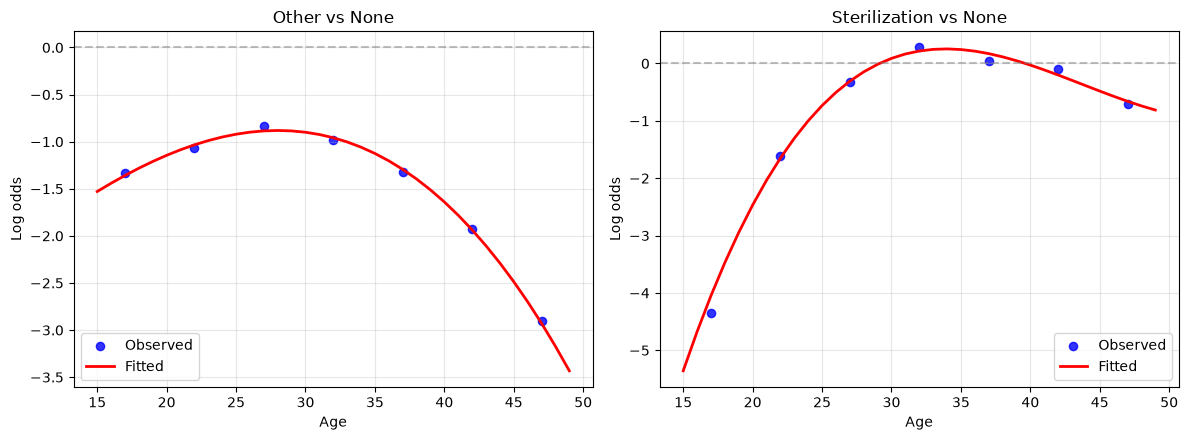

In [170]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

categories = [
    ('Other', lo_other_obs, lo_other),
    ('Sterilization', lo_steril_obs, lo_steril)
]

for ax, (category, obs, fitted) in zip(axes, categories):
    # Observed log odds
    ax.scatter(tab['Agen'], obs, color='blue',
               label='Observed', s=35, alpha=0.8)

    # Fitted log odds
    ax.plot(Agen_pred, fitted, color='red',
            label='Fitted', linewidth=2)

    ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
    ax.set_xlabel('Age')
    ax.set_ylabel('Log odds')
    ax.set_title(f'{category} vs None')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [171]:
Agec40 = (40 - 32) / 5
pred40 = pd.DataFrame({'Agec': [Agec40]})
Xnew_40 = patsy.dmatrix('Agec + I(Agec**2) + I(Agec**3)', pred40, return_type='dataframe')
fm3_pred40 = fm3.predict(Xnew_40)
print(fm3_pred40)

          0         1         2
0  0.461753  0.089613  0.448634


In [172]:
print(fm3_pred40[2] / fm3_pred40[1])

0    5.006367
dtype: float64


In [173]:
agec = (40-32)/5
p1 = 0.2164+0.1998*agec-0.2855*agec**2+0.0405*agec**3
p2 = -0.9579-0.1969*agec-0.1317*agec**2-0.0072*agec**3
np.exp(p1-p2)

np.float64(5.0061702418887215)

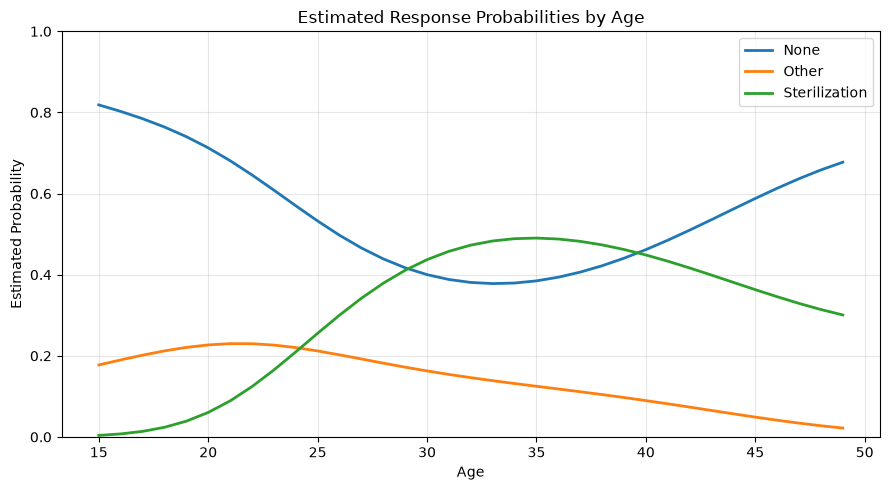

In [174]:
plt.figure(figsize=(9, 5))

categories = ['None', 'Other', 'Sterilization']

for i, category in enumerate(categories):
    plt.plot(Agen_pred, fm3_pred.iloc[:, i],
             linewidth=2, label=category)

plt.xlabel('Age')
plt.ylabel('Estimated Probability')
plt.title('Estimated Response Probabilities by Age')
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [176]:
tab['Any'] = tab['Sterilization'] + tab['Other']
tab['None_cnt'] = tab['None']
tab['Agen'] = tab['Age'].str.extract(r'(\d+)\s*-\s*(\d+)').astype(float).mean(axis=1)
tab['Agec'] = (tab['Agen'] - 32) / 5

In [178]:
fm0 = glm('Any + None_cnt ~ 1', tab, family=Binomial()).fit()
fm1 = update_glm(fm0, add='Agec')
fm2 = update_glm(fm1, add='I(Agec**2)')
fm3 = update_glm(fm2, add='I(Agec**3)')
fm4 = update_glm(fm3, add='I(Agec**4)')
fm5 = update_glm(fm4, add='I(Agec**5)')
fm6 = update_glm(fm5, add='I(Agec**6)')
anova_nested(fm0, fm1, fm2, fm3, fm4, fm5, fm6)

c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
Model 1,6.0,2.188388e+02,NaN,NaN,NaN
Model 2,5.0,1.808546e+02,1.0,37.984177,7.132069e-10
Model 3,4.0,6.119465e+00,1.0,174.735175,6.839712e-40
Model 4,3.0,6.041849e+00,1.0,0.077617,7.805534e-01
Model 5,2.0,3.150511e+00,1.0,2.891337,8.905699e-02
Model 6,1.0,1.136427e+00,1.0,2.014084,1.558453e-01
Model 7,0.0,-9.614531e-14,1.0,1.136427,2.864086e-01


In [179]:
print(fm2.summary2(),'\n')

               Results: Generalized linear model
Model:              GLM                 Method:         IRLS   
Model Family:       Binomial            AIC:            57.0704
Link Function:      Logit               BIC:            56.9081
Dependent Variable: ['Any', 'None_cnt'] Log-Likelihood: -25.535
Date:               2026-11-24 16:36    LL-Null:        -131.89
No. Observations:   7                   Deviance:       6.1195 
Df Model:           2                   Pearson chi2:   6.12   
Df Residuals:       4                   Scale:          1.0000 
---------------------------------------------------------------
                Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
---------------------------------------------------------------
Intercept       0.4095   0.0525   7.8042 0.0000  0.3067  0.5124
Agec            0.1367   0.0216   6.3320 0.0000  0.0944  0.1790
I(Agec ** 2)   -0.1586   0.0125 -12.7108 0.0000 -0.1831 -0.1342
 



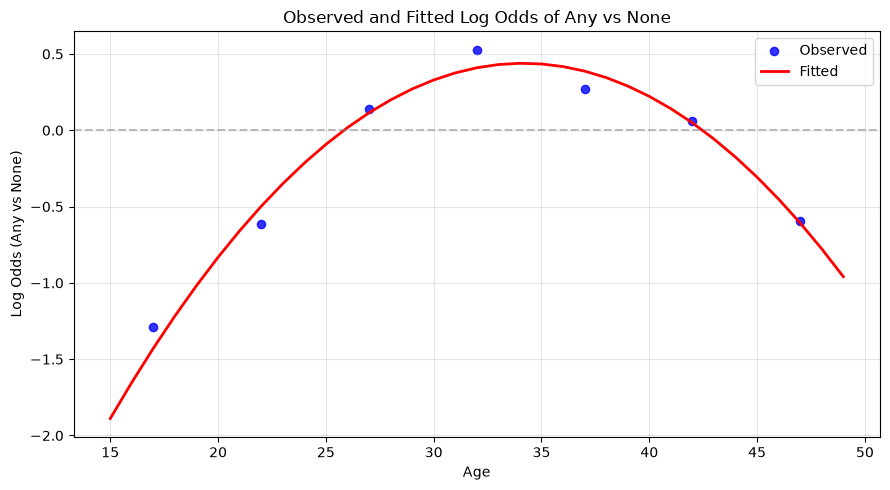

In [180]:
df_pred = pd.DataFrame({'Agec': Agec_pred})
p_pred = fm2.predict(df_pred)
lo_pred = np.log(p_pred / (1 - p_pred))
lo_obs = np.log(tab['Any'] / tab['None_cnt'])

plt.figure(figsize=(9, 5))

plt.scatter(tab['Agen'], lo_obs, color='blue',
            label='Observed', s=35, alpha=0.8)

plt.plot(Agen_pred, lo_pred, color='red',
         label='Fitted', linewidth=2)

plt.axhline(0, color='gray', linestyle='--', alpha=0.5)

plt.xlabel('Age')
plt.ylabel('Log Odds (Any vs None)')
plt.title('Observed and Fitted Log Odds of Any vs None')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [181]:
chi2.sf(fm2.deviance, fm2.df_resid)

np.float64(0.1904024017122776)

In [183]:
fm0 = glm('Sterilization + Other ~ 1', tab, family=Binomial()).fit()
fm1 = update_glm(fm0, add='Agec')
fm2 = update_glm(fm1, add='I(Agec**2)')
fm3 = update_glm(fm2, add='I(Agec**3)')
fm4 = update_glm(fm3, add='I(Agec**4)')
fm5 = update_glm(fm4, add='I(Agec**5)')
fm6 = update_glm(fm5, add='I(Agec**6)')
anova_nested(fm0, fm1, fm2, fm3, fm4, fm5, fm6)

c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
Model 1,6.0,3.022638e+02,NaN,NaN,NaN
Model 2,5.0,4.161491e+01,1.0,260.648943,1.238976e-58
Model 3,4.0,1.077352e+01,1.0,30.841390,2.800016e-08
Model 4,3.0,2.129860e+00,1.0,8.643656,3.282022e-03
Model 5,2.0,1.935556e+00,1.0,0.194303,6.593591e-01
Model 6,1.0,1.804838e+00,1.0,0.130718,7.176883e-01
Model 7,0.0,4.685141e-14,1.0,1.804838,1.791287e-01


In [184]:
print(fm3.summary2(),'\n')

                  Results: Generalized linear model
Model:              GLM                        Method:         IRLS   
Model Family:       Binomial                   AIC:            45.4531
Link Function:      Logit                      BIC:            45.2367
Dependent Variable: ['Sterilization', 'Other'] Log-Likelihood: -18.727
Date:               2026-11-24 16:39           LL-Null:        -168.79
No. Observations:   7                          Deviance:       2.1299 
Df Model:           3                          Pearson chi2:   2.10   
Df Residuals:       3                          Scale:          1.0000 
------------------------------------------------------------------------
                Coef.    Std.Err.      z      P>|z|     [0.025    0.975]
------------------------------------------------------------------------
Intercept       1.1738     0.0844   13.9011   0.0000    1.0083    1.3393
Agec            0.3971     0.0894    4.4397   0.0000    0.2218    0.5724
I(Agec ** 2)   

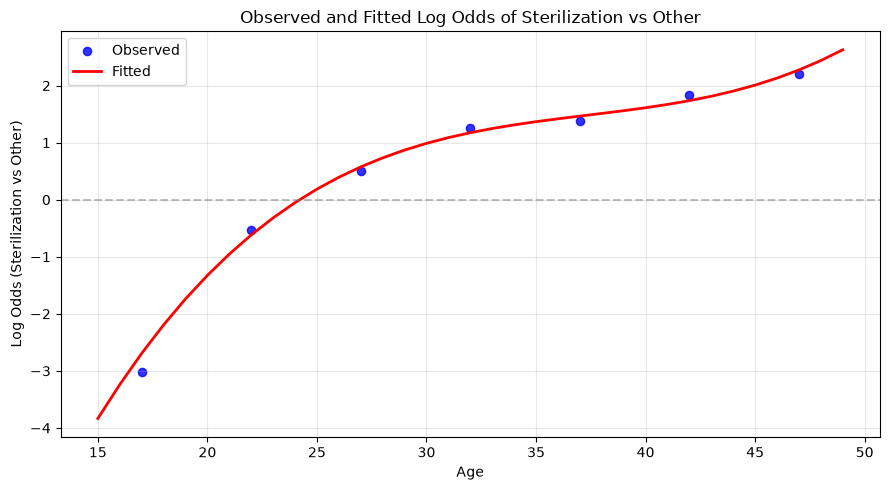

In [185]:
p_pred = fm3.predict(df_pred)
lo_pred = np.log(p_pred / (1 - p_pred))
lo_obs = np.log(tab['Sterilization'] / tab['Other'])

plt.figure(figsize=(9, 5))

plt.scatter(tab['Agen'], lo_obs, color='blue',
            label='Observed', s=35, alpha=0.8)

plt.plot(Agen_pred, lo_pred, color='red',
         label='Fitted', linewidth=2)

plt.axhline(0, color='gray', linestyle='--', alpha=0.5)

plt.xlabel('Age')
plt.ylabel('Log Odds (Sterilization vs Other)')
plt.title('Observed and Fitted Log Odds of Sterilization vs Other')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [186]:
chi2.sf(fm3.deviance, fm3.df_resid)

np.float64(0.5458956311816272)

### Assignment 2

In [29]:
df = pd.read_csv('dataset/menarche.txt', sep=' ')
df.head()

,Age,Total,Menarche
0,9.21,376,0
1,10.21,200,0
2,10.58,93,0
3,10.83,120,2
4,11.08,90,2


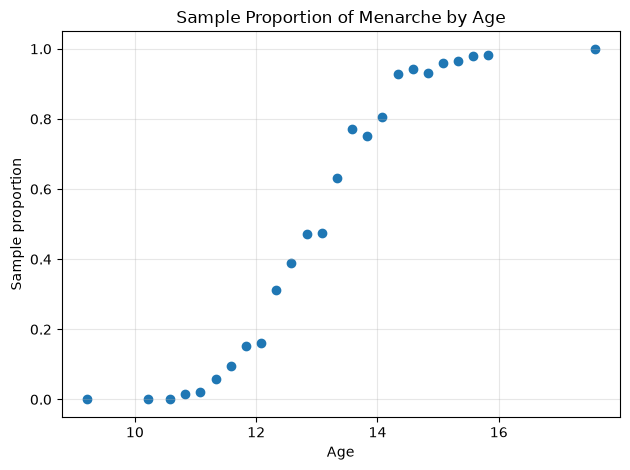

In [30]:
df['prop'] = df['Menarche'] / df['Total']

plt.scatter(df['Age'], df['prop'])
plt.xlabel('Age')
plt.ylabel('Sample proportion')
plt.title('Sample Proportion of Menarche by Age')
plt.grid(True, alpha=0.3)
plt.ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

In [31]:
df['fail'] = df['Total'] - df['Menarche']
fm0 = glm('Menarche + fail ~ 1', df, family=Binomial()).fit()
fm1 = update_glm(fm0, add='Age')
fm2 = update_glm(fm1, add='I(Age**2)')
fm3 = update_glm(fm2, add='I(Age**3)') # selected
fm4 = update_glm(fm3, add='I(Age**4)')

anova_nested(fm0, fm1, fm2, fm3, fm4)

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
Model 1,24.0,3693.883575,NaN,NaN,NaN
Model 2,23.0,26.703452,1.0,3667.180123,0.000000
Model 3,22.0,23.202068,1.0,3.501384,0.061318
Model 4,21.0,15.044541,1.0,8.157527,0.004288
Model 5,20.0,14.654940,1.0,0.389601,0.532509


In [32]:
fm0_probit = glm('Menarche + fail ~ 1', df, family=Binomial(link=Probit())).fit()
fm1_probit = update_glm(fm0_probit, add='Age')
fm2_probit = update_glm(fm1_probit, add='I(Age**2)') # selected
fm3_probit = update_glm(fm2_probit, add='I(Age**3)')

anova_nested(fm0_probit, fm1_probit, fm2_probit, fm3_probit)

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
Model 1,24.0,3693.883575,NaN,NaN,NaN
Model 2,23.0,22.887433,1.0,3670.996142,0.000000
Model 3,22.0,15.148752,1.0,7.738681,0.005405
Model 4,21.0,14.092838,1.0,1.055914,0.304149


In [33]:
fm3.aic, fm2_probit.aic

(np.float64(107.09634405709603), np.float64(105.20055453268716))

In [35]:
print(fm2_probit.params)

Intercept     -20.183212
Age             2.185452
I(Age ** 2)    -0.048391
dtype: float64


In [36]:
chi2.sf(fm2_probit.deviance, fm2_probit.df_resid)

np.float64(0.8557755401015874)

In [37]:
df['log_age_9'] = np.log(df['Age']-9)
df['log_18_age'] = np.log(18-df['Age'])

fm_new = glm('Menarche + fail ~ log_age_9 + log_18_age', df, family=Binomial()).fit()
print(fm_new.params)

Intercept    -2.593525
log_age_9     4.434702
log_18_age   -2.146731
dtype: float64


In [38]:
chi2.sf(fm_new.deviance, fm_new.df_resid)

np.float64(0.876471056149878)

In [39]:
fm_new.aic

np.float64(104.71032568377802)

In [40]:
def f(x):
    pred_df = pd.DataFrame({'log_age_9': np.log([x-9]), 'log_18_age': np.log([18-x])}) 
    pred_value = fm_new.predict(pred_df, which='linear')[0]
    return pred_value - logit(p)

p = 0.9
age90 = root_scalar(f, bracket=[min(df['Age']), max(df['Age'])], method='brentq')
print(age90.root)


14.443652010598106


In [41]:
def compute_sd(x, beta):
    dm = beta[1]/(x-9) - beta[2]/(18-x)  # denominator
    h = np.array([-1/dm, -np.log(x-9)/dm, -np.log(18-x)/dm])
    sd_x = np.sqrt(h @ np.array(fm_new.cov_params()) @ h)
    return sd_x

beta = np.array(fm_new.params)
print(compute_sd(age90.root, beta))

0.07129974813890703


In [2]:
df = pd.read_csv('dataset/satisfaction.csv')
df.head()

,Satisfied,Notsatisfied,Gender,Race,Age,Region
0,288,177,M,W,<35,NE
1,90,45,M,W,<35,MA
2,226,128,M,W,<35,S
3,285,179,M,W,<35,MW
4,270,180,M,W,<35,NW


In [3]:
df['Gender'] = pd.Categorical(df['Gender'], categories=['F', 'M'], ordered=True)
df['Race'] = pd.Categorical(df['Race'], categories=['O', 'W'], ordered=True)
df['Age'] = pd.Categorical(df['Age'], categories=['<35', '35-44', '>44'], ordered=True)
df['Region'] = pd.Categorical(df['Region'], categories=['MA', 'NE', 'S', 'MW', 'NW', 'SW', 'P'], ordered=True)

In [4]:
fm = glm('Satisfied + Notsatisfied ~ (Gender + Race + Age + Region)**4', df, family=Binomial()).fit()
drop1_glm(fm)

c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linea

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,4.305189e-09,533.009216,,
Gender:Race:Age:Region,12,1.995873e+01,528.967950,19.958734,0.067871


In [5]:
fm = update_glm(fm, drop='Gender:Race:Age:Region')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,19.958734,528.967950,,
Gender:Race:Age,2,23.737710,528.746926,3.778976,0.151149
Gender:Race:Region,6,23.171554,520.180771,3.212821,0.781701
Gender:Age:Region,12,39.906394,524.915611,19.947661,0.068083
Race:Age:Region,12,39.734348,524.743565,19.775615,0.071451


In [6]:
fm = update_glm(fm, drop='Gender:Race:Region')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,23.171554,520.180771,,
Gender:Race:Age,2,27.563138,520.572354,4.391584,0.11127
Gender:Age:Region,12,43.429816,516.439032,20.258262,0.062356
Race:Age:Region,12,42.341849,515.351065,19.170295,0.084501


In [7]:
fm = update_glm(fm, drop='Gender:Race:Age')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,27.563138,520.572354,,
Gender:Race,1,35.680163,526.689379,8.117025,0.004385
Gender:Age:Region,12,48.025277,517.034494,20.462139,0.058833
Race:Age:Region,12,45.858581,514.867798,18.295443,0.10701


In [8]:
fm = update_glm(fm, drop='Race:Age:Region')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,45.858581,514.867798,,
Gender:Race,1,53.437687,520.446903,7.579105,0.005905
Race:Age,2,47.088807,512.098023,1.230225,0.54058
Race:Region,6,50.142851,507.152067,4.28427,0.638267
Gender:Age:Region,12,66.031779,511.040995,20.173198,0.06388


In [9]:
fm = update_glm(fm, drop='Race:Region')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,50.142851,507.152067,,
Gender:Race,1,57.262244,512.271460,7.119393,0.007625
Race:Age,2,51.036427,504.045643,0.893576,0.63968
Gender:Age:Region,12,70.414110,503.423326,20.271259,0.062126


In [10]:
fm = update_glm(fm, drop='Race:Age')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,51.036427,504.045643,,
Gender:Race,1,58.476925,509.486141,7.440498,0.006377
Gender:Age:Region,12,71.037436,500.046653,20.001009,0.067067


In [11]:
fm = update_glm(fm, drop='Gender:Age:Region')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,71.037436,500.046653,,
Gender:Race,1,77.790092,504.799308,6.752655,0.009361
Gender:Age,2,76.852847,501.862063,5.815411,0.054601
Gender:Region,6,74.197320,491.206536,3.159884,0.788529
Age:Region,12,79.019943,484.029159,7.982507,0.786496


In [12]:
fm = update_glm(fm, drop='Gender:Region')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,74.197320,491.206536,,
Gender:Race,1,81.995960,497.005176,7.79864,0.005229
Gender:Age,2,79.785846,492.795062,5.588526,0.06116
Age:Region,12,81.967599,474.976816,7.770279,0.802815


In [13]:
fm = update_glm(fm, drop='Age:Region')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,81.967599,474.976816,,
Region,6,120.229073,501.238289,38.261474,0.000001
Gender:Race,1,89.561766,480.570983,7.594167,0.005856
Gender:Age,2,87.941035,476.950251,5.973435,0.050453


In [14]:
fm = update_glm(fm, drop='Gender:Age')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,87.941035,476.950251,,
Age,2,138.242651,523.251867,50.301616,0.0
Region,6,126.030905,503.040122,38.089871,0.000001
Gender:Race,1,97.516346,484.525562,9.575312,0.001972


In [15]:
print(fm.summary2(),'\n')

                    Results: Generalized linear model
Model:              GLM                           Method:         IRLS    
Model Family:       Binomial                      AIC:            476.9503
Link Function:      Logit                         BIC:            506.1201
Dependent Variable: ['Satisfied', 'Notsatisfied'] Log-Likelihood: -226.48 
Date:               2026-11-25 09:27              LL-Null:        -284.58 
No. Observations:   84                            Deviance:       87.941  
Df Model:           11                            Pearson chi2:   84.5    
Df Residuals:       72                            Scale:          1.0000  
---------------------------------------------------------------------------
                        Coef.   Std.Err.     z     P>|z|    [0.025   0.975]
---------------------------------------------------------------------------
Intercept               0.4310    0.1217   3.5399  0.0004   0.1924   0.6696
Gender[T.M]             0.4903    0.1112  

In [16]:
np.exp(fm.params[5:11])

Region[T.NE]    0.646381
Region[T.S]     0.770106
Region[T.MW]    0.705075
Region[T.NW]    0.731126
Region[T.SW]    0.862342
Region[T.P]     0.975774
dtype: float64

In [17]:
fm2 = glm('Satisfied + Notsatisfied ~ Gender + Race + Age + Region', df, family=Binomial(link=Probit())).fit()
print(fm2.summary2(),'\n')

                    Results: Generalized linear model
Model:              GLM                           Method:         IRLS    
Model Family:       Binomial                      AIC:            484.7811
Link Function:      Probit                        BIC:            511.5201
Dependent Variable: ['Satisfied', 'Notsatisfied'] Log-Likelihood: -231.39 
Date:               2026-11-25 09:28              LL-Null:        -284.58 
No. Observations:   84                            Deviance:       97.772  
Df Model:           10                            Pearson chi2:   93.4    
Df Residuals:       73                            Scale:          1.0000  
----------------------------------------------------------------------------
                    Coef.    Std.Err.      z      P>|z|     [0.025    0.975]
----------------------------------------------------------------------------
Intercept           0.3634     0.0676    5.3745   0.0000    0.2309    0.4959
Gender[T.M]         0.1107     0.0294 

In [19]:
beta = np.array(fm2.params)[:3]
zeta = sum(beta)
p = norm.cdf(zeta)
print(p)

0.6833784214815958


In [23]:
h = np.array([norm.pdf(zeta), norm.pdf(zeta), norm.pdf(zeta)])
sd_p = np.sqrt(h @ np.array(fm2.cov_params())[:3, :3] @ h)
p + np.array([-1,1]) * norm.ppf(0.975) * sd_p

array([0.64252676, 0.72423008])

In [24]:
h = np.array([1, 1, 1])
sd_zeta = np.sqrt(h @ np.array(fm2.cov_params())[:3, :3] @ h)
zeta_CI = zeta + np.array([-1,1]) * norm.ppf(0.975) * sd_zeta
norm.cdf(zeta_CI)

array([0.64148091, 0.72304595])

In [25]:
chi2.sf(fm2.deviance, fm2.df_resid)

np.float64(0.028111308365711272)

In [27]:
print(fm2.deviance, fm2.df_resid)

97.77187502880088 73


In [28]:
fm2.deviance/fm2.df_resid

np.float64(1.3393407538191902)

### Assignment 3

In [47]:
195+46
979+370
195+979
46+370
195+979+46+370
1174+241-1590

-175

In [48]:
M = 1590
n = 241
N = 1174

p_list = stats.hypergeom.pmf(range(0, 242), M=M, n=n, N=N)
p195=p_list[195]

print(p195)
print(sum(p_list[p_list<=p195]))

0.001423480678571258
0.0067227552226850834


In [49]:
nij = np.array([[104, 10], [22, 2]])
muhat = np.outer(nij.sum(axis=1), nij.sum(axis=0)) / nij.sum()

X2 = ((nij - muhat)**2 / muhat).sum()
print(X2, chi2.sf(X2, 1))

0.004803675856307418 0.944744015864725


In [50]:
nij = np.array([[91, 36], [957, 368]])
muhat = np.outer(nij.sum(axis=1), nij.sum(axis=0)) / nij.sum()

G2 = 2 * (nij * np.log(nij/muhat)).sum()
print(G2, chi2.sf(G2, 1))

0.01887392798731069 0.8907285299418354


In [51]:
df = pd.DataFrame(list(product(['Both parents', 'Mother only'], ['B', 'W'], ['M', 'F'], [1, 2], ['N', 'S'])), 
                  columns=['F', 'R', 'G', 'A', 'S'])
df['Count'] = [27, 2, 12, 2, 23, 4, 7, 1, 
               394, 32, 142, 19, 421, 38, 94, 11,
               18, 1, 13, 1, 24, 0, 4, 3,
               48, 6, 25, 4, 55, 15, 13, 4]
df[['F', 'R', 'G', 'A', 'S']] = df[['F', 'R', 'G', 'A', 'S']].astype('category')
df.head()

,F,R,G,A,S,Count
0,Both parents,B,M,1,N,27
1,Both parents,B,M,1,S,2
2,Both parents,B,M,2,N,12
3,Both parents,B,M,2,S,2
4,Both parents,B,F,1,N,23


In [52]:
fm = glm(formula='Count ~ (F + R + G + A + S)**5', data=df, family=Poisson()).fit()
drop1_glm(fm)

c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,4.691567e-09,201.681384,,
F:R:G:A:S,1,3.638905e+00,203.320289,3.638905,0.056444


In [53]:
fm = update_glm(fm, drop='F:R:G:A:S')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,3.638905,203.320289,,
F:R:G:A,1,3.708219,201.389604,0.069314,0.792338
F:R:G:S,1,3.844518,201.525902,0.205612,0.650228
F:R:A:S,1,6.270808,203.952192,2.631903,0.104736
F:G:A:S,1,4.264350,201.945734,0.625445,0.429031
R:G:A:S,1,3.991229,201.672613,0.352324,0.552801


In [54]:
fm = update_glm(fm, drop='F:R:G:A')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,3.708219,201.389604,,
F:R:G:S,1,3.988333,199.669717,0.280114,0.596627
F:R:A:S,1,6.272211,201.953595,2.563992,0.109322
F:G:A:S,1,4.372985,200.054369,0.664765,0.414883
R:G:A:S,1,4.086900,199.768284,0.37868,0.53831


In [55]:
fm = update_glm(fm, drop='F:R:G:S')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,3.988333,199.669717,,
F:R:G,1,4.093347,197.774731,0.105014,0.745894
F:R:A:S,1,6.685475,200.366860,2.697142,0.100528
F:G:A:S,1,4.502332,198.183717,0.513999,0.473413
R:G:A:S,1,4.199296,197.880680,0.210963,0.646014


In [56]:
fm = update_glm(fm, drop='F:R:G')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,4.093347,197.774731,,
F:R:A:S,1,6.833659,198.515043,2.740312,0.097846
F:G:A:S,1,4.639732,196.321117,0.546386,0.459798
R:G:A:S,1,4.342070,196.023455,0.248723,0.617975


In [57]:
fm = update_glm(fm, drop='R:G:A:S')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,4.342070,196.023455,,
R:G:A,1,4.409247,194.090632,0.067177,0.795492
R:G:S,1,4.657215,194.338600,0.315145,0.57454
F:R:A:S,1,7.349332,197.030717,3.007262,0.082892
F:G:A:S,1,5.030993,194.712378,0.688923,0.406531


In [58]:
fm = update_glm(fm, drop='R:G:S')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,4.657215,194.338600,,
R:G:A,1,4.691905,192.373289,0.03469,0.852247
F:R:A:S,1,7.711777,195.393162,3.054562,0.080511
F:G:A:S,1,5.537633,193.219018,0.880418,0.348087


In [59]:
fm = update_glm(fm, drop='F:G:A:S')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,5.537633,193.219018,,
F:G:A,1,6.603769,192.285153,1.066136,0.30182
F:G:S,1,8.123313,193.804697,2.58568,0.107834
R:G:A,1,5.582112,191.263496,0.044479,0.832966
G:A:S,1,5.591351,191.272735,0.053717,0.816717
F:R:A:S,1,8.541894,194.223278,3.004261,0.083046


In [60]:
fm = update_glm(fm, drop='G:A:S')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,5.591351,191.272735,,
F:G:A,1,6.692369,190.373754,1.101019,0.294043
F:G:S,1,8.140539,191.821923,2.549188,0.110351
R:G:A,1,5.636214,189.317599,0.044864,0.832255
F:R:A:S,1,8.595396,192.276780,3.004045,0.083057


In [61]:
fm = update_glm(fm, drop='F:G:A')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,6.692369,190.373754,,
F:G:S,1,9.026551,190.707936,2.334182,0.126561
R:G:A,1,6.955171,188.636556,0.262802,0.608202
F:R:A:S,1,9.746061,191.427446,3.053692,0.080554


In [62]:
fm = update_glm(fm, drop='F:G:S')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,9.026551,190.707936,,
F:G,1,9.565444,189.246828,0.538893,0.462892
G:S,1,10.614407,190.295792,1.587856,0.207633
R:G:A,1,9.191102,188.872486,0.16455,0.685001
F:R:A:S,1,11.999639,191.681023,2.973087,0.08466


In [63]:
fm = update_glm(fm, drop='F:G')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,9.565444,189.246828,,
G:S,1,11.292980,188.974364,1.727536,0.188726
R:G:A,1,9.724144,187.405528,0.1587,0.690357
F:R:A:S,1,12.537681,190.219065,2.972237,0.084705


In [64]:
fm = update_glm(fm, drop='G:S')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,11.292980,188.974364,,
R:G:A,1,11.424154,187.105539,0.131175,0.717217
F:R:A:S,1,14.265216,189.946601,2.972237,0.084705


In [65]:
fm = update_glm(fm, drop='F:R:A:S')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,14.265216,189.946601,,
F:R:A,1,14.300729,187.982113,0.035512,0.850526
F:R:S,1,18.196847,191.878231,3.93163,0.047386
F:A:S,1,14.268519,187.949904,0.003303,0.95417
R:G:A,1,14.396391,188.077775,0.131175,0.717217
R:A:S,1,15.409442,189.090826,1.144225,0.284761


In [66]:
fm = update_glm(fm, drop='F:A:S')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,14.268519,187.949904,,
F:R:A,1,14.305619,185.987004,0.0371,0.847262
F:R:S,1,18.298268,189.979652,4.029748,0.044705
R:G:A,1,14.399694,186.081078,0.131175,0.717217
R:A:S,1,15.414132,187.095516,1.145613,0.284469


In [67]:
fm = update_glm(fm, drop='F:R:A')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,14.305619,185.987004,,
F:A,1,15.703296,185.384680,1.397677,0.237113
F:R:S,1,18.301762,187.983147,3.996143,0.045605
R:G:A,1,14.436794,184.118178,0.131175,0.717217
R:A:S,1,15.433464,185.114849,1.127845,0.288235


In [68]:
fm = update_glm(fm, drop='R:A:S')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,15.433464,185.114849,,
F:A,1,16.688557,184.369941,1.255092,0.262582
A:S,1,19.338734,187.020118,3.90527,0.048135
F:R:S,1,19.248028,186.929412,3.814564,0.050809
R:G:A,1,15.564639,183.246023,0.131175,0.717217


In [69]:
fm = update_glm(fm, drop='F:A')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,16.688557,184.369941,,
A:S,1,20.937546,186.618931,4.24899,0.039274
F:R:S,1,20.492670,186.174054,3.804113,0.051127
R:G:A,1,16.819731,182.501116,0.131175,0.717217


In [70]:
fm = update_glm(fm, drop='F:R:S')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,20.492670,186.174054,,
F:R,1,97.428375,261.109759,76.935705,0.0
F:S,1,27.402014,191.083398,6.909344,0.008575
R:S,1,21.062605,184.743989,0.569935,0.450285
A:S,1,24.741660,188.423044,4.24899,0.039274
R:G:A,1,20.623844,184.305229,0.131175,0.717217


In [71]:
fm = update_glm(fm, drop='R:S')
drop1_glm(fm)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,21.062605,184.743989,,
F:R,1,97.432132,259.113516,76.369527,0.0
F:S,1,27.405771,189.087155,6.343166,0.011783
A:S,1,25.177468,186.858852,4.114863,0.042508
R:G:A,1,21.193779,182.875164,0.131175,0.717217


In [95]:
chi2.sf(fm.deviance, fm.df_resid)

np.float64(0.33335198490933565)

In [72]:
print(fm.summary2(),'\n')

                   Results: Generalized linear model
Model:                   GLM                 Method:            IRLS    
Model Family:            Poisson             AIC:               184.7440
Link Function:           Log                 BIC:               203.7986
Dependent Variable:      Count               Log-Likelihood:    -79.372 
Date:                    2026-11-25 10:40    LL-Null:           -1803.2 
No. Observations:        32                  Deviance:          21.063  
Df Model:                12                  Pearson chi2:      19.2    
Df Residuals:            19                  Scale:             1.0000  
------------------------------------------------------------------------
                         Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
------------------------------------------------------------------------
Intercept                3.2521   0.1595  20.3837 0.0000  2.9394  3.5649
F[T.Mother only]        -0.2626   0.1711  -1.5345 0.1249 -0.5979  0.072

In [73]:
np.exp(0.5520)

np.float64(1.736722992721326)

In [92]:
df.pivot_table(index=['F', 'R'], columns='S', values='Count', aggfunc='sum')

S                  N    S
F            R           
Both parents B    69    9
             W  1051  100
Mother only  B    59    5
             W   141   29

In [76]:
fm2 = glm(formula='Count ~ (F + R + G + A + S)**5', data=df, family=Poisson()).fit()
drop1_glm(fm2)

c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\regression\_tools.py:133: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\YuxinLi\anaconda3\envs\ST5213\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,4.691567e-09,201.681384,,
F:R:G:A:S,1,3.638905e+00,203.320289,3.638905,0.056444


In [77]:
fm2 = update_glm(fm2, drop='F:R:G:A:S')
drop1_glm(fm2)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,3.638905,203.320289,,
F:R:G:A,1,3.708219,201.389604,0.069314,0.792338
F:R:G:S,1,3.844518,201.525902,0.205612,0.650228
F:R:A:S,1,6.270808,203.952192,2.631903,0.104736
F:G:A:S,1,4.264350,201.945734,0.625445,0.429031
R:G:A:S,1,3.991229,201.672613,0.352324,0.552801


In [78]:
fm2 = update_glm(fm2, drop='F:R:G:S')
drop1_glm(fm2)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,3.844518,201.525902,,
F:R:G:A,1,3.988333,199.669717,0.143815,0.704517
F:R:A:S,1,6.667043,202.348428,2.822526,0.09295
F:G:A:S,1,4.339614,200.020999,0.495097,0.481663
R:G:A:S,1,4.056734,199.738118,0.212216,0.645036


In [79]:
fm2 = update_glm(fm2, drop='R:G:A:S')
drop1_glm(fm2)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,4.056734,199.738118,,
R:G:S,1,4.442341,198.123725,0.385607,0.534618
F:R:G:A,1,4.199296,197.880680,0.142562,0.705747
F:R:A:S,1,7.168104,200.849488,3.11137,0.077748
F:G:A:S,1,4.665529,198.346914,0.608795,0.435242


In [80]:
fm2 = update_glm(fm2, drop='R:G:S')
drop1_glm(fm2)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,4.442341,198.123725,,
F:R:G:A,1,4.538320,196.219704,0.095979,0.756709
F:R:A:S,1,7.550684,199.232069,3.108344,0.077892
F:G:A:S,1,5.261367,196.942751,0.819026,0.365465


In [81]:
fm2 = update_glm(fm2, drop='F:G:A:S')
drop1_glm(fm2)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,5.261367,196.942751,,
F:G:S,1,7.992275,197.673659,2.730908,0.098423
G:A:S,1,5.327200,195.008584,0.065833,0.797503
F:R:G:A,1,5.368691,195.050075,0.107324,0.743212
F:R:A:S,1,8.343346,198.024730,3.081979,0.079164


In [82]:
fm2 = update_glm(fm2, drop='G:A:S')
drop1_glm(fm2)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,5.327200,195.008584,,
F:G:S,1,8.013994,195.695378,2.686794,0.101183
F:R:G:A,1,5.430203,193.111587,0.103003,0.748256
F:R:A:S,1,8.401719,196.083103,3.074519,0.079528


In [83]:
fm2 = update_glm(fm2, drop='F:G:S')
drop1_glm(fm2)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,8.013994,195.695378,,
G:S,1,9.660778,195.342162,1.646784,0.199397
F:R:G:A,1,8.061357,193.742741,0.047363,0.827717
F:R:A:S,1,11.009366,196.690750,2.995372,0.083503


In [84]:
fm2 = update_glm(fm2, drop='G:S')
drop1_glm(fm2)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,9.660778,195.342162,,
F:R:G:A,1,9.690705,193.372090,0.029927,0.862655
F:R:A:S,1,12.633015,196.314399,2.972237,0.084705


In [85]:
fm2 = update_glm(fm2, drop='F:R:A:S')
drop1_glm(fm2)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,12.633015,196.314399,,
F:R:S,1,16.564645,198.246029,3.93163,0.047386
F:A:S,1,12.636317,194.317702,0.003303,0.95417
R:A:S,1,13.777240,195.458624,1.144225,0.284761
F:R:G:A,1,12.662942,194.344326,0.029927,0.862655


In [86]:
fm2 = update_glm(fm2, drop='F:A:S')
drop1_glm(fm2)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,12.636317,194.317702,,
F:R:S,1,16.666066,196.347450,4.029748,0.044705
R:A:S,1,13.781930,193.463314,1.145613,0.284469
F:R:G:A,1,12.666245,192.347629,0.029927,0.862655


In [87]:
fm2 = update_glm(fm2, drop='R:A:S')
drop1_glm(fm2)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,13.781930,193.463314,,
A:S,1,17.706227,195.387611,3.924297,0.047593
F:R:S,1,17.615097,195.296481,3.833166,0.050248
F:R:G:A,1,13.811858,191.493242,0.029927,0.862655


In [88]:
fm2 = update_glm(fm2, drop='F:R:S')
drop1_glm(fm2)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,17.615097,195.296481,,
F:S,1,24.170695,199.852079,6.555598,0.010455
R:S,1,18.156456,193.837840,0.541359,0.46187
A:S,1,21.510340,197.191724,3.895244,0.048423
F:R:G:A,1,17.645024,193.326408,0.029927,0.862655


In [89]:
fm2 = update_glm(fm2, drop='R:S')
drop1_glm(fm2)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,18.156456,193.837840,,
F:S,1,24.174452,197.855836,6.017996,0.014161
A:S,1,21.946148,195.627532,3.789692,0.051569
F:R:G:A,1,18.186383,191.867768,0.029927,0.862655


In [90]:
fm2 = update_glm(fm2, drop='A:S')
drop1_glm(fm2)

,Df,Deviance,AIC,LRT,Pr(>Chi)
<none>,,21.946148,195.627532,,
F:S,1,28.420961,200.102346,6.474813,0.010941
F:R:G:A,1,21.976075,193.657460,0.029927,0.862655


In [93]:
print(fm2.summary2(),'\n')

                          Results: Generalized linear model
Model:                       GLM                      Method:                 IRLS    
Model Family:                Poisson                  AIC:                    195.6275
Link Function:               Log                      BIC:                    222.0108
Dependent Variable:          Count                    Log-Likelihood:         -79.814 
Date:                        2026-11-25 10:51         LL-Null:                -1803.2 
No. Observations:            32                       Deviance:               21.946  
Df Model:                    17                       Pearson chi2:           20.0    
Df Residuals:                14                       Scale:                  1.0000  
--------------------------------------------------------------------------------------
                                       Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
----------------------------------------------------------------------

In [96]:
chi2.sf(fm2.deviance, fm2.df_resid)

np.float64(0.07972767576835059)

In [94]:
np.exp(0.5578)

np.float64(1.7468252543177483)

In [74]:
df.pivot_table(index='F', columns='S', values='Count', aggfunc='sum')

S,N,S
F,,
Both parents,1120,109
Mother only,200,34


In [75]:
1120*34/(200*109)

1.7467889908256882

In [97]:
np.exp(4.0204), np.exp(0.1365)

(np.float64(55.723390725809026), np.float64(1.1462548777757673))

In [98]:
2177.441-2162.507

14.933999999999742

In [99]:
2162.507-2085.782

76.72499999999991

In [100]:
2085.782-2085.584

0.19800000000032014

In [113]:
2099.224-2085.782

13.442000000000007

In [101]:
1.388245+1.177108, -0.2201856-0.3525769, -1.118289-1.159847

(2.565353, -0.5727625000000001, -2.278136)

In [102]:
np.exp([-0.5727625000000001, -2.278136])

array([0.56396533, 0.10247504])

In [108]:
p1=np.exp(3.3074)/(1+np.exp(3.3074))
p2=np.exp(3.4818)/(1+np.exp(3.4818))-p1
p3=np.exp(5.3494)/(1+np.exp(5.3494))-p1-p2
p4=np.exp(7.2563)/(1+np.exp(7.2563))-p1-p2-p3
p5=1-p1-p2-p3-p4
[p1, p2, p3, p4, p5]

[np.float64(0.9646818036040071),
 np.float64(0.005483660692845671),
 np.float64(0.02510600023383469),
 np.float64(0.004023318796787079),
 np.float64(0.0007052166725254327)]

In [116]:
CI = -0.5463+np.array([-1,1])*1.96*0.0272
print(CI)
print(np.exp(CI))

[-0.599612 -0.492988]
[0.54902462 0.6107986 ]


In [118]:
1/np.exp(-0.7602-0.1244)

np.float64(2.4220153915418643)

In [120]:
1/np.exp(-0.7602)

np.float64(2.1387039185092935)

In [110]:
np.exp(-0.1244)

np.float64(0.8830265596073633)

In [125]:
p1 = 9/11
p2 = 1/6
log_p = np.log(p1/p2)
log_p + np.array([-1,1])*1.96*np.sqrt((1-p1)/9+(1-p2)/1)

array([-0.21969598,  3.40187352])

In [127]:
M = 17
n = 11
N = 10

p_list = stats.hypergeom.pmf(range(4, 11), M=M, n=n, N=N)
p9=p_list[5]

print(p_list)
print(sum(p_list[5:]))

[0.01696833 0.14253394 0.35633484 0.33936652 0.12726244 0.01696833
 0.00056561]
0.01753393665158371


In [128]:
np.exp(0.3918)

np.float64(1.479641753456789)

In [129]:
2713.5/647

4.193972179289026

In [130]:
phi=2713.5/647
0.391808+np.array([-1,1])*1.96*0.008122*np.sqrt(phi)

array([0.35920693, 0.42440907])

In [132]:
p=1-np.exp(-np.exp(-3.89315))

In [133]:
b0=-3.89315
h=np.exp(-np.exp(b0))*np.exp(b0)
se=h*0.03002
p+np.array([-1,1])*1.96*se

array([0.01899974, 0.02134977])

In [134]:
np.exp(-0.8571960)

np.float64(0.42435029389067536)

In [135]:
-0.8571960+np.array([-1,1])*1.96*0.20733213

array([-1.26356697, -0.45082503])

In [137]:
np.exp(-0.541)
np.exp(-0.541-1.044)

np.float64(0.2049477931167973)

In [4]:
b0=-3.89315
p=1-np.exp(-np.exp(b0))
se=np.exp(-np.exp(b0))*np.exp(b0)*0.03002
p+np.array([-1,1])*1.96*se

array([0.01899974, 0.02134977])

In [7]:
3.558681e-05/2

1.7793405e-05

In [8]:
np.exp(-1.044)

np.float64(0.3520436871019846)

In [9]:
(4-1)*48-18

126

In [12]:
z=4.42-5.461-0.354*10+0.286*10
p1=np.exp(z)/(1+np.exp(z))
z=5.981-5.461-0.354*10+0.286*10
p2=np.exp(z)/(1+np.exp(z))
p2-p1

np.float64(0.3083427132647679)

In [13]:
2*(-41.46+46.88)

10.840000000000003

In [ ]:
np.exp(0.1365)
2085.782-2085.584
2099.224-2085.782
2162.507-2085.782
1.388245+1.177108, -0.2201856-0.3525769, -1.118289-1.159847
np.exp(-0.2201856-0.3525769), np.exp(-1.118289-1.159847)
p1=np.exp(3.3074)/(1+np.exp(3.3074))
p2=np.exp(3.4818)/(1+np.exp(3.4818))-p1
p3=np.exp(5.3494)/(1+np.exp(5.3494))-p1-p2
p4=np.exp(7.2563)/(1+np.exp(7.2563))-p1-p2-p3
p5=1-p1-p2-p3-p4
p1, p2, p3, p4, p5
-0.5463-1.96*0.0272, -0.5463+1.96*0.0272
np.exp([-0.5463-1.96*0.0272, -0.5463+1.96*0.0272])
np.exp(-0.7602), np.exp(-0.7602-0.1244)
np.exp(-0.1244)

np.exp(0.391808)
2713.5/647
0.391808-1.96*0.008122*np.sqrt(4.1940), 0.391808+1.96*0.008122*np.sqrt(4.1940)
b0=-3.89315
p=1-np.exp(-np.exp(b0))
se=np.exp(-np.exp(b0))*np.exp(b0)*0.03002
p-1.96*se, p+1.96*se
z=np.log(9/11/(1/6))
se=np.sqrt((1-9/11)/9+(1-1/6)/1)
z-1.96*se, z+1.96*se
# (11 9)(6 1)/(17 10)
p1=11*10/2*6/(factorial(17)/(factorial(10)*factorial(7)))
p2=11/(factorial(17)/(factorial(10)*factorial(7)))
p1+p2
np.exp(-0.8572)
3.5587e-05/2
np.exp(-0.541)
np.exp(-0.541-1.044)
48*3-3*6
np.exp(-0.367)/(1+np.exp(-0.299)+np.exp(-0.367)+np.exp(-2.052))
np.exp(1.649), np.exp(-0.325), np.exp(2.277)
np.exp(2.559)
np.exp(0.483)
4.42-5.461-0.354*10+0.286*10, 5.981-5.461-0.354*10+0.286*10
np.exp(-1.721)/(1+np.exp(-1.721))
np.exp(-0.16)/(1+np.exp(-0.16))-np.exp(-1.721)/(1+np.exp(-1.721))
2*(-41.46+46.88)
np.exp(3.77058)/(1+np.exp(3.77058)), np.exp(0.26328)/(1+np.exp(0.26328))

1.77935e-05